# EDA toàn diện 3 dataset: NASDAQ · NYSE · S&P 500

**Dự án:** PTDLKD_Ki5 — phân tích dữ liệu cổ phiếu cho bài toán dự báo / stock ranking.

**Mục tiêu:** Hiểu cấu trúc dữ liệu, toàn vẹn, bao phủ, phân phối đặc trưng, biến động theo thời gian, lợi suất, khác biệt giữa ba dataset, rủi ro và các lưu ý trước khi xây dựng mô hình. Tất cả các tệp CSV mã cổ phiếu NASDAQ/NYSE sẽ được quét (mặc định không giới hạn); S&P 500 được ưu tiên đọc bằng `.npy` theo từng cổ phiếu để tiết kiệm RAM.

**Nguồn được đối chiếu (29/10/2026):**
- [Script tải và chuyển đổi dữ liệu trong PTDLKD_Ki5](https://raw.githubusercontent.com/Bondyyy/PTDLKD_Ki5/main/downloadAllDatasets_with_csv.py)
- [Temporal Relational Stock Ranking](https://github.com/fulifeng/Temporal_Relational_Stock_Ranking) (NASDAQ, NYSE)
- [StockMixer](https://github.com/SJTU-DMTai/StockMixer) (S&P 500)

> ⚠️ **Đọc trước khi diễn giải:**
> - NASDAQ/NYSE: file `NASDAQ_AAPL_1.csv` có **6 cột không header**: cột 0 là chỉ số bước thời gian, 5 cột tiếp theo là đặc trưng đã xử lý. Không có ngày giao dịch và OHLCV gốc trong các CSV này. Ở đây tên `feature_0` … `feature_4`; **cột cuối được dùng như `price_proxy`** để tính return tham khảo, KHÔNG mặc định đó là giá USD.
> - S&P 500: `SP500.npy` là tensor (stock × time × feature). StockMixer dùng kênh cuối làm chuỗi giá đầu vào để tính tỷ suất; ta sẽ dùng kênh cuối làm `price_proxy`, đồng thời ghi rõ đây là giả định theo mã mô hình.
> - `baseline_data_sp500.csv` (nếu có) là nguồn để đọc OHLCV/ngày thực. Không tự unpickle `baseline_data_sp500.npy` vì tải từ nguồn bên ngoài có thể thực thi code khi `allow_pickle=True`.
> - **KHÔNG** so sánh trực tiếp giá trị tuyệt đối của các đặc trưng ở 3 bộ nếu chưa xác nhận cùng đơn vị và tiền xử lý. Việc chuẩn hóa bằng max toàn giai đoạn còn có thể gây leakage nếu thực hiện trước chia tập.

**Đầu ra:** biểu đồ PNG trong `Anh/EDA/`, CSV tóm tắt và báo cáo JSON trong `Anh/EDA/reports/` (tạo tự động). Cứ chạy **Run All**.

## 1. Cài đặt và nhận diện đường dẫn

Chỉ cần `numpy`, `pandas`, `matplotlib`, `IPython`, `jupyter`. Notebook tự tìm `dataset_original/` trong thư mục đang mở hoặc thư mục cha. Có thể sửa `DATA_ROOT` nếu đặt notebook nơi khác.

In [1]:
from pathlib import Path
import json, math, re, sys, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.grid': True,
                     'grid.alpha': .25, 'savefig.dpi': 160,
                     'font.size': 10, 'figure.autolayout': True})
RNG = np.random.default_rng(2026)

# ---- Cấu hình ----
DATA_ROOT = None    # Ví dụ: Path(r'D:\NCKH\PTDLKD\dataset_original')
MAX_TICKERS_PER_MARKET = None  # None = đọc TOÀN BỘ, số nguyên để test nhanh
SAMPLE_ROWS_PER_STOCK = 50     # chỉ giảm điểm VẼ; không giảm số file được quét
MAX_HEATMAP_STOCKS = 35
MAX_BASELINE_SAMPLE = 50000    # số dòng tối đa giữ để vẽ từ baseline CSV
OUTLIER_RETURN_THRESHOLD = 0.20 # biên lợi suất >= 20%/bước: cảnh báo, không mặc định lỗi
SAVE_FIGURES = True

candidates = []
if DATA_ROOT is not None:
    candidates.append(Path(DATA_ROOT))
for start in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent, Path(r'D:\NCKH\PTDLKD')]:
    candidates.extend([start / 'dataset_original', start])
DATA_ROOT = next((x.resolve() for x in candidates if
                  all((x / m).is_dir() for m in ('NASDAQ', 'NYSE', 'SP500'))), None)
if DATA_ROOT is None:
    raise FileNotFoundError('Không tìm được dataset_original/NASDAQ, NYSE, SP500. '
                            'Hãy sửa DATA_ROOT ở cell cấu hình thành đường dẫn trên máy.')
PROJECT_ROOT = DATA_ROOT.parent
FIG_DIR = PROJECT_ROOT / 'Anh' / 'EDA'
REPORT_DIR = FIG_DIR / 'reports'
FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_SAVED = []

def savefig(name):
    if SAVE_FIGURES:
        dest = FIG_DIR / f'{name}.png'
        plt.savefig(dest, bbox_inches='tight', dpi=170)
        FIGURES_SAVED.append(str(dest.relative_to(PROJECT_ROOT)))
    plt.show()
    plt.close()

def report(name, df, sort_by=None, ascending=False):
    if df is None or len(df) == 0:
        return
    out = df.sort_values(sort_by, ascending=ascending) if sort_by in df.columns else df
    out.to_csv(REPORT_DIR / f'{name}.csv', index=False, encoding='utf-8-sig')

def safe_num(v):
    try:
        x = float(v)
        return x if np.isfinite(x) else None
    except (TypeError, ValueError):
        return None

display(Markdown(f'**Data root:** `{DATA_ROOT}`  \n**Ảnh và báo cáo:** `{FIG_DIR}`'))
print('Python:', sys.version.split()[0], '| numpy:', np.__version__, '| pandas:', pd.__version__)

**Data root:** `D:\NCKH\PTDLKD\dataset_original`  
**Ảnh và báo cáo:** `D:\NCKH\PTDLKD\Anh\EDA`

Python: 3.12.10 | numpy: 2.5.4 | pandas: 2.2.3


## 2. Inventory / thống kê cấu trúc thư mục

Đếm số file, dung lượng, dữ liệu thiếu và các file nguồn. Bảng này giúp kiểm tra repo đã tải đủ hay chưa; số lượng ticker kỳ vọng NASDAQ **1.026**, NYSE **1.737** từ mô tả nguồn.

In [2]:
inventory = []
for market in ['NASDAQ', 'NYSE', 'SP500']:
    folder = DATA_ROOT / market
    paths = [p for p in folder.iterdir() if p.is_file()]
    sizes = [p.stat().st_size for p in paths]
    inventory.append({'dataset': market,
                      'file_count': len(paths),
                      'files_empty': int(sum(s == 0 for s in sizes)),
                      'total_MB': round(sum(sizes) / 1024**2, 2),
                      'csv_count': sum(p.suffix.lower()=='.csv' for p in paths),
                      'npy_count': sum(p.suffix.lower()=='.npy' for p in paths),
                      'example_files': ', '.join(p.name for p in sorted(paths)[:4])})
file_overview = pd.DataFrame(inventory)
display(file_overview)
report('00_file_inventory', file_overview)
for market in ['NASDAQ', 'NYSE']:
    folder = DATA_ROOT / market
    found = list(folder.glob(f'{market}_*_1.csv'))
    exp = 1026 if market == 'NASDAQ' else 1737
    print(f'{market}: {len(found):,}/{exp:,} tệp chuỗi; '
          f'thiếu {max(exp-len(found),0):,} tệp so với nguồn gốc (nếu danh sách giống phiên bản gốc).')

,dataset,file_count,files_empty,total_MB,csv_count,npy_count,example_files
0,NASDAQ,1027,0,69.66,1027,0,"NASDAQ_AABA_1.csv, NASDAQ_AAON_1.csv, NASDAQ_A..."
1,NYSE,1738,0,117.81,1738,0,"NYSE_A_1.csv, NYSE_AAN_1.csv, NYSE_AAP_1.csv, ..."
2,SP500,5,0,354.04,3,2,"baseline_data_sp500.csv, baseline_data_sp500.n..."


NASDAQ: 1,026/1,026 tệp chuỗi; thiếu 0 tệp so với nguồn gốc (nếu danh sách giống phiên bản gốc).
NYSE: 1,737/1,737 tệp chuỗi; thiếu 0 tệp so với nguồn gốc (nếu danh sách giống phiên bản gốc).


## 3. Bộ đọc và hàm thống kê cơ sở

- Đọc CSV chuỗi gốc **không dùng hàng đầu làm header**; kiểm tra cột time.
- Tính `return_t = P_t/P_{t-1}-1` chỉ trên các cặp giá hữu hạn và dương, không nối qua đoạn bị thiếu.
- Dùng `max drawdown`, volatility, autocorrelation, chênh lệch tích lũy, tính mất cân bằng tăng/giảm.
- Không gọi 0 là missing tuyệt đối; đưa vào bảng `zero_fraction` để kiểm tra.

In [3]:
def read_market_file(path):
    x = pd.read_csv(path, header=None, low_memory=False)
    # Hỗ trợ trường hợp tệp được sửa và bổ sung header; nhận diện 1 hàng không numeric.
    if len(x) and pd.to_numeric(x.iloc[0], errors='coerce').isna().mean() > .75:
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 2:
        raise ValueError(f'File chỉ có {x.shape[1]} cột')
    x = x.apply(pd.to_numeric, errors='coerce')
    day = x.iloc[:, 0].to_numpy(dtype=float)
    if not (np.isfinite(day).mean() > .95 and np.all(np.isclose(day[np.isfinite(day)],
                                                                    np.rint(day[np.isfinite(day)])))):
        day = np.arange(len(x), dtype=float)
    features = x.iloc[:, 1:].to_numpy(dtype=float)
    return day, features

def pct_returns(price):
    p = np.asarray(price, dtype=float)
    r = np.full(p.shape, np.nan, dtype=float)
    if len(p) > 1:
        good = np.isfinite(p[:-1]) & np.isfinite(p[1:]) & (p[:-1] > 0) & (p[1:] > 0)
        r[1:][good] = p[1:][good] / p[:-1][good] - 1
    return r

def max_drawdown(price):
    v = np.asarray(price, dtype=float)
    v = v[np.isfinite(v) & (v > 0)]
    if len(v) < 2: return np.nan
    return float(np.min(v / np.maximum.accumulate(v) - 1.0))

def lag_corr(v, lag=1):
    v = np.asarray(v, dtype=float)
    if len(v) <= lag: return np.nan
    a, b = v[:-lag], v[lag:]
    good = np.isfinite(a) & np.isfinite(b)
    if good.sum() < 5 or np.std(a[good]) < 1e-12 or np.std(b[good]) < 1e-12:
        return np.nan
    return float(np.corrcoef(a[good], b[good])[0, 1])

def summarize_stock(market, stock, day, feat):
    feat = np.asarray(feat, dtype=float)
    price = feat[:, -1]
    rets = pct_returns(price)
    finite = rets[np.isfinite(rets)]
    valid_price = price[np.isfinite(price) & (price > 0)]
    d = np.asarray(day, dtype=float)
    nd = d[np.isfinite(d)]
    start, end = (valid_price[0], valid_price[-1]) if len(valid_price) else (np.nan, np.nan)
    all_nan = ~np.isfinite(feat)
    return {
        'dataset':market, 'ticker':str(stock), 'rows':len(feat), 'n_features':feat.shape[1],
        'time_first':float(nd[0]) if len(nd) else np.nan,
        'time_last':float(nd[-1]) if len(nd) else np.nan,
        'duplicate_time_index':int(len(nd) - len(np.unique(nd))),
        'time_not_monotonic':int(np.any(np.diff(nd) < 0)) if len(nd)>1 else 0,
        'missing_feature_cells':int(all_nan.sum()),
        'missing_fraction':float(np.mean(all_nan)) if feat.size else np.nan,
        'zero_fraction':float(np.mean(feat == 0)) if feat.size else np.nan,
        'negative_fraction':float(np.mean(feat < 0)) if feat.size else np.nan,
        'price_proxy_positive_fraction':float(len(valid_price)/len(price)) if len(price) else np.nan,
        'price_proxy_min':float(np.nanmin(price)) if np.isfinite(price).any() else np.nan,
        'price_proxy_max':float(np.nanmax(price)) if np.isfinite(price).any() else np.nan,
        'valid_return_count':len(finite),
        'daily_return_mean':float(finite.mean()) if len(finite) else np.nan,
        'daily_return_std':float(finite.std(ddof=1)) if len(finite)>1 else np.nan,
        'daily_return_median':float(np.median(finite)) if len(finite) else np.nan,
        'positive_return_rate':float(np.mean(finite > 0)) if len(finite) else np.nan,
        'negative_return_rate':float(np.mean(finite < 0)) if len(finite) else np.nan,
        'zero_return_rate':float(np.mean(finite == 0)) if len(finite) else np.nan,
        'outlier_20pct_rate':float(np.mean(np.abs(finite) >= OUTLIER_RETURN_THRESHOLD)) if len(finite) else np.nan,
        'return_q01':float(np.quantile(finite, .01)) if len(finite) else np.nan,
        'return_q99':float(np.quantile(finite, .99)) if len(finite) else np.nan,
        'return_autocorr_lag1':lag_corr(rets),
        'max_drawdown':max_drawdown(price),
        'whole_period_proxy_change':float(end/start-1) if np.isfinite(start) and start>0 and np.isfinite(end) else np.nan
    }

def sample_rows(market, ticker, day, feat):
    take = min(len(day), SAMPLE_ROWS_PER_STOCK)
    if take == 0: return None
    ids = np.sort(RNG.choice(len(day), take, replace=False))
    cols = {f'feature_{j}':feat[ids,j] for j in range(feat.shape[1])}
    return pd.DataFrame({'dataset':market, 'ticker':str(ticker),
                         'time_index':np.asarray(day)[ids], 'price_proxy':feat[ids,-1],
                         'return_1d':pct_returns(feat[:,-1])[ids], **cols})

def build_matrix(series_list):
    # Dùng cùng trục time_index nguyên cho các stock, không gọi đó là lịch thực.
    union = np.unique(np.concatenate([np.rint(x[0][np.isfinite(x[0])]).astype(int)
                                        for x in series_list if np.isfinite(x[0]).any()]))
    union = union[(union >= 0) & (union <= 100000)]
    mat = np.full((len(series_list), len(union)), np.nan, dtype=np.float32)
    pos = {int(d):j for j,d in enumerate(union)}
    for i,(days,price) in enumerate(series_list):
        for t,v in zip(days, price):
            if np.isfinite(t) and int(round(t)) in pos:
                mat[i,pos[int(round(t))]] = v
    return union, mat

def get_matrix_returns(m):
    m = np.asarray(m, dtype=float)
    r = np.full_like(m, np.nan)
    if m.shape[1] > 1:
        a,b=m[:,:-1],m[:,1:]
        mask=np.isfinite(a)&np.isfinite(b)&(a>0)&(b>0)
        np.divide(b, a, out=r[:,1:], where=mask)
        r[:,1:][mask] -= 1
        r[:,1:][~mask] = np.nan
    return r

## 4. Đọc TOÀN BỘ NASDAQ & NYSE và kiểm tra chất lượng

Mặc định quét toàn bộ các file từng cổ phiếu, giữ ở RAM **một ma trận price_proxy** phục vụ vẽ theo thời gian, chứ không ghép toàn bộ 5+ triệu ô đặc trưng thành bảng khổng lồ. Các ảnh phân phối chỉ lấy mẫu cố định sau khi đã tính thống kê cho từng mã.

In [4]:
MARKET_STATS = {}
SAMPLES = {}
MATRICES = {}
LOAD_ERRORS = []

for market in ['NASDAQ', 'NYSE']:
    folder = DATA_ROOT / market
    paths = sorted(folder.glob(f'{market}_*_1.csv'))
    if MAX_TICKERS_PER_MARKET is not None:
        paths = paths[:int(MAX_TICKERS_PER_MARKET)]
    rows, sam, series, names = [], [], [], []
    for i,p in enumerate(paths,1):
        try:
            days,features=read_market_file(p)
            ticker=p.name[len(market)+1:-len('_1.csv')]
            rows.append(summarize_stock(market,ticker,days,features))
            sampled=sample_rows(market,ticker,days,features)
            if sampled is not None: sam.append(sampled)
            series.append((days,features[:,-1]))
            names.append(ticker)
        except Exception as ex:
            LOAD_ERRORS.append({'dataset':market,'file':p.name,'error':str(ex)})
        if i%300==0 or i==len(paths):
            print(f'{market}: {i:,}/{len(paths):,} file')
    MARKET_STATS[market] = pd.DataFrame(rows)
    SAMPLES[market] = pd.concat(sam, ignore_index=True) if sam else pd.DataFrame()
    if series:
        d,m=build_matrix(series)
        MATRICES[market]={'day':d,'price':m,'tickers':names,'returns':get_matrix_returns(m)}
    print(f'  Thành công {len(rows):,} file | lỗi {sum(e["dataset"]==market for e in LOAD_ERRORS):,}')
    report(f'01_{market.lower()}_per_stock',MARKET_STATS[market],sort_by='missing_fraction')

all_stocks = pd.concat([df for df in MARKET_STATS.values() if not df.empty],ignore_index=True)
all_samples = pd.concat([df for df in SAMPLES.values() if not df.empty],ignore_index=True)
report('01_load_errors',pd.DataFrame(LOAD_ERRORS))
print('Tổng cổ phiếu có dữ liệu:',len(all_stocks))
display(all_stocks.groupby('dataset').agg(n_stocks=('ticker','size'),
    median_rows=('rows','median'), min_rows=('rows','min'), max_rows=('rows','max'),
    missing_cell_rate_mean=('missing_fraction','mean'),
    zero_cell_rate_mean=('zero_fraction','mean'),
    median_valid_price_rate=('price_proxy_positive_fraction','median')).round(5))

NASDAQ: 300/1,026 file


NASDAQ: 600/1,026 file


NASDAQ: 900/1,026 file


NASDAQ: 1,026/1,026 file


  Thành công 1,026 file | lỗi 0


...

NYSE: 1,200/1,737 file


NYSE: 1,500/1,737 file


NYSE: 1,737/1,737 file


  Thành công 1,737 file | lỗi 0
Tổng cổ phiếu có dữ liệu: 2763


,n_stocks,median_rows,min_rows,max_rows,missing_cell_rate_mean,zero_cell_rate_mean,median_valid_price_rate
dataset,,,,,,,
NASDAQ,1026,1246.0,1246,1246,0.0,0.0,0.9992
NYSE,1737,1245.0,1245,1245,0.0,0.0,1.0000


## 5. Data Quality EDA — thiếu, trùng, 0, âm, độ dài chuỗi

Những thứ phải kiểm tra **trước khi** train: tệp thiếu, stock có ít lịch sử, hàng trùng time_index, giá proxy 0/âm, lỗi thiếu feature. Cột đã normalize có thể chứa 0 hợp lệ; không xóa tùy tiện.

,dataset,stocks,rows_total,rows_median,rows_min,rows_max,missing_pct,zero_pct,negative_pct,stocks_with_missing,stocks_with_duplicate_day,stocks_unordered_day,positive_price_pct
0,NASDAQ,1026,1278396,1246.0,1246,1246,0.0,0.0,0.140,0,0,0,99.828
1,NYSE,1737,2162565,1245.0,1245,1245,0.0,0.0,0.052,0,0,0,99.936


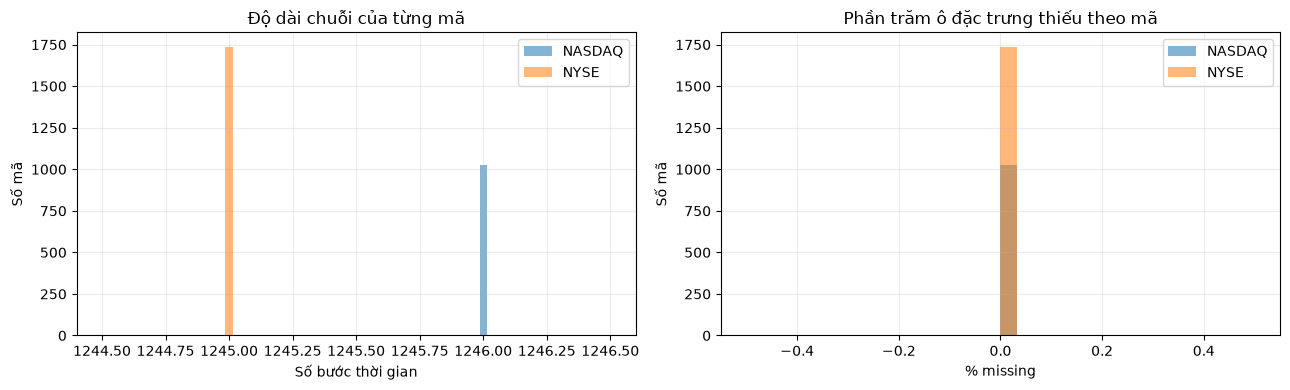

### NASDAQ: 15 mã cần rà soát (missing, dữ liệu ngắn)

,ticker,rows,missing_fraction,zero_fraction,negative_fraction,duplicate_time_index,price_proxy_positive_fraction
0,AABA,1246,0.0,0.0,0.000803,0,0.999197
1,AAON,1246,0.0,0.0,0.000803,0,0.999197
2,AAPL,1246,0.0,0.0,0.000803,0,0.999197
3,AAWW,1246,0.0,0.0,0.000803,0,0.999197
4,AAXJ,1246,0.0,0.0,0.000803,0,0.999197
5,AAXN,1246,0.0,0.0,0.000803,0,0.999197
6,ABAX,1246,0.0,0.0,0.000803,0,0.999197
7,ABCB,1246,0.0,0.0,0.000803,0,0.999197
8,ABCO,1246,0.0,0.0,0.012039,0,0.987961
9,ABMD,1246,0.0,0.0,0.001605,0,0.998395


### NYSE: 15 mã cần rà soát (missing, dữ liệu ngắn)

,ticker,rows,missing_fraction,zero_fraction,negative_fraction,duplicate_time_index,price_proxy_positive_fraction
0,A,1245,0.0,0.0,0.000000,0,1.000000
1,AAN,1245,0.0,0.0,0.000000,0,1.000000
2,AAP,1245,0.0,0.0,0.000000,0,1.000000
3,AAT,1245,0.0,0.0,0.000000,0,1.000000
4,AB,1245,0.0,0.0,0.000000,0,1.000000
5,ABB,1245,0.0,0.0,0.000000,0,1.000000
6,ABBV,1245,0.0,0.0,0.011245,0,0.988755
7,ABC,1245,0.0,0.0,0.000000,0,1.000000
8,ABG,1245,0.0,0.0,0.000000,0,1.000000
9,ABM,1245,0.0,0.0,0.000000,0,1.000000


In [5]:
if len(all_stocks):
    quality=all_stocks.groupby('dataset').agg(
        stocks=('ticker','size'),rows_total=('rows','sum'),
        rows_median=('rows','median'),rows_min=('rows','min'),rows_max=('rows','max'),
        missing_pct=('missing_fraction',lambda x:100*x.mean()),
        zero_pct=('zero_fraction',lambda x:100*x.mean()),
        negative_pct=('negative_fraction',lambda x:100*x.mean()),
        stocks_with_missing=('missing_fraction',lambda x:int((x>0).sum())),
        stocks_with_duplicate_day=('duplicate_time_index',lambda x:int((x>0).sum())),
        stocks_unordered_day=('time_not_monotonic','sum'),
        positive_price_pct=('price_proxy_positive_fraction',lambda x:100*x.mean())
    ).reset_index()
    display(quality.round(3))
    report('02_quality_summary',quality)
    fig,ax=plt.subplots(1,2,figsize=(13,4))
    for m,g in all_stocks.groupby('dataset'):
        ax[0].hist(g['rows'].dropna(),bins=35,alpha=.55,label=m)
        ax[1].hist(100*g['missing_fraction'].dropna(),bins=30,alpha=.55,label=m)
    ax[0].set(title='Độ dài chuỗi của từng mã',xlabel='Số bước thời gian',ylabel='Số mã')
    ax[1].set(title='Phần trăm ô đặc trưng thiếu theo mã',xlabel='% missing',ylabel='Số mã')
    for a in ax:a.legend()
    savefig('01_length_and_missing_distribution')
    for m in ('NASDAQ','NYSE'):
        display(Markdown(f'### {m}: 15 mã cần rà soát (missing, dữ liệu ngắn)'))
        display(MARKET_STATS[m].sort_values(['missing_fraction','rows'],ascending=[False,True])
               [['ticker','rows','missing_fraction','zero_fraction','negative_fraction',
                 'duplicate_time_index','price_proxy_positive_fraction']].head(15))

## 6. Phân phối của 5 đặc trưng NASDAQ & NYSE

Kiểm tra mean/median/std, phân phối, tỷ lệ 0 và tương quan. **Feature_4** chỉ là tên kỹ thuật — được dùng làm `price_proxy` để phân tích chuỗi; notebook không tự gán nhãn `close` khi chưa xác minh metadata của bản tiền xử lý.

,dataset,feature,n_sample,missing_pct,zero_pct,mean,median,std,q01,q99
0,NASDAQ,feature_0,51300,0.0,0.0,-0.85134,0.65374,42.89672,0.15589,0.98592
1,NASDAQ,feature_1,51300,0.0,0.0,-0.85206,0.65323,42.89669,0.15624,0.98388
2,NASDAQ,feature_2,51300,0.0,0.0,-0.85341,0.65228,42.89664,0.15547,0.98064
3,NASDAQ,feature_3,51300,0.0,0.0,-0.85469,0.65173,42.89659,0.15529,0.97900
4,NASDAQ,feature_4,51300,0.0,0.0,-1.45252,0.65400,50.80199,0.15258,0.98793
5,NYSE,feature_0,86850,0.0,0.0,0.15388,0.75507,26.49272,0.24583,0.98173
6,NYSE,feature_1,86850,0.0,0.0,0.15346,0.75469,26.49271,0.24733,0.97987
7,NYSE,feature_2,86850,0.0,0.0,0.15277,0.75420,26.49270,0.24769,0.97763
8,NYSE,feature_3,86850,0.0,0.0,0.15213,0.75384,26.49268,0.24761,0.97608
9,NYSE,feature_4,86850,0.0,0.0,-0.11591,0.75525,32.17156,0.24386,0.98352


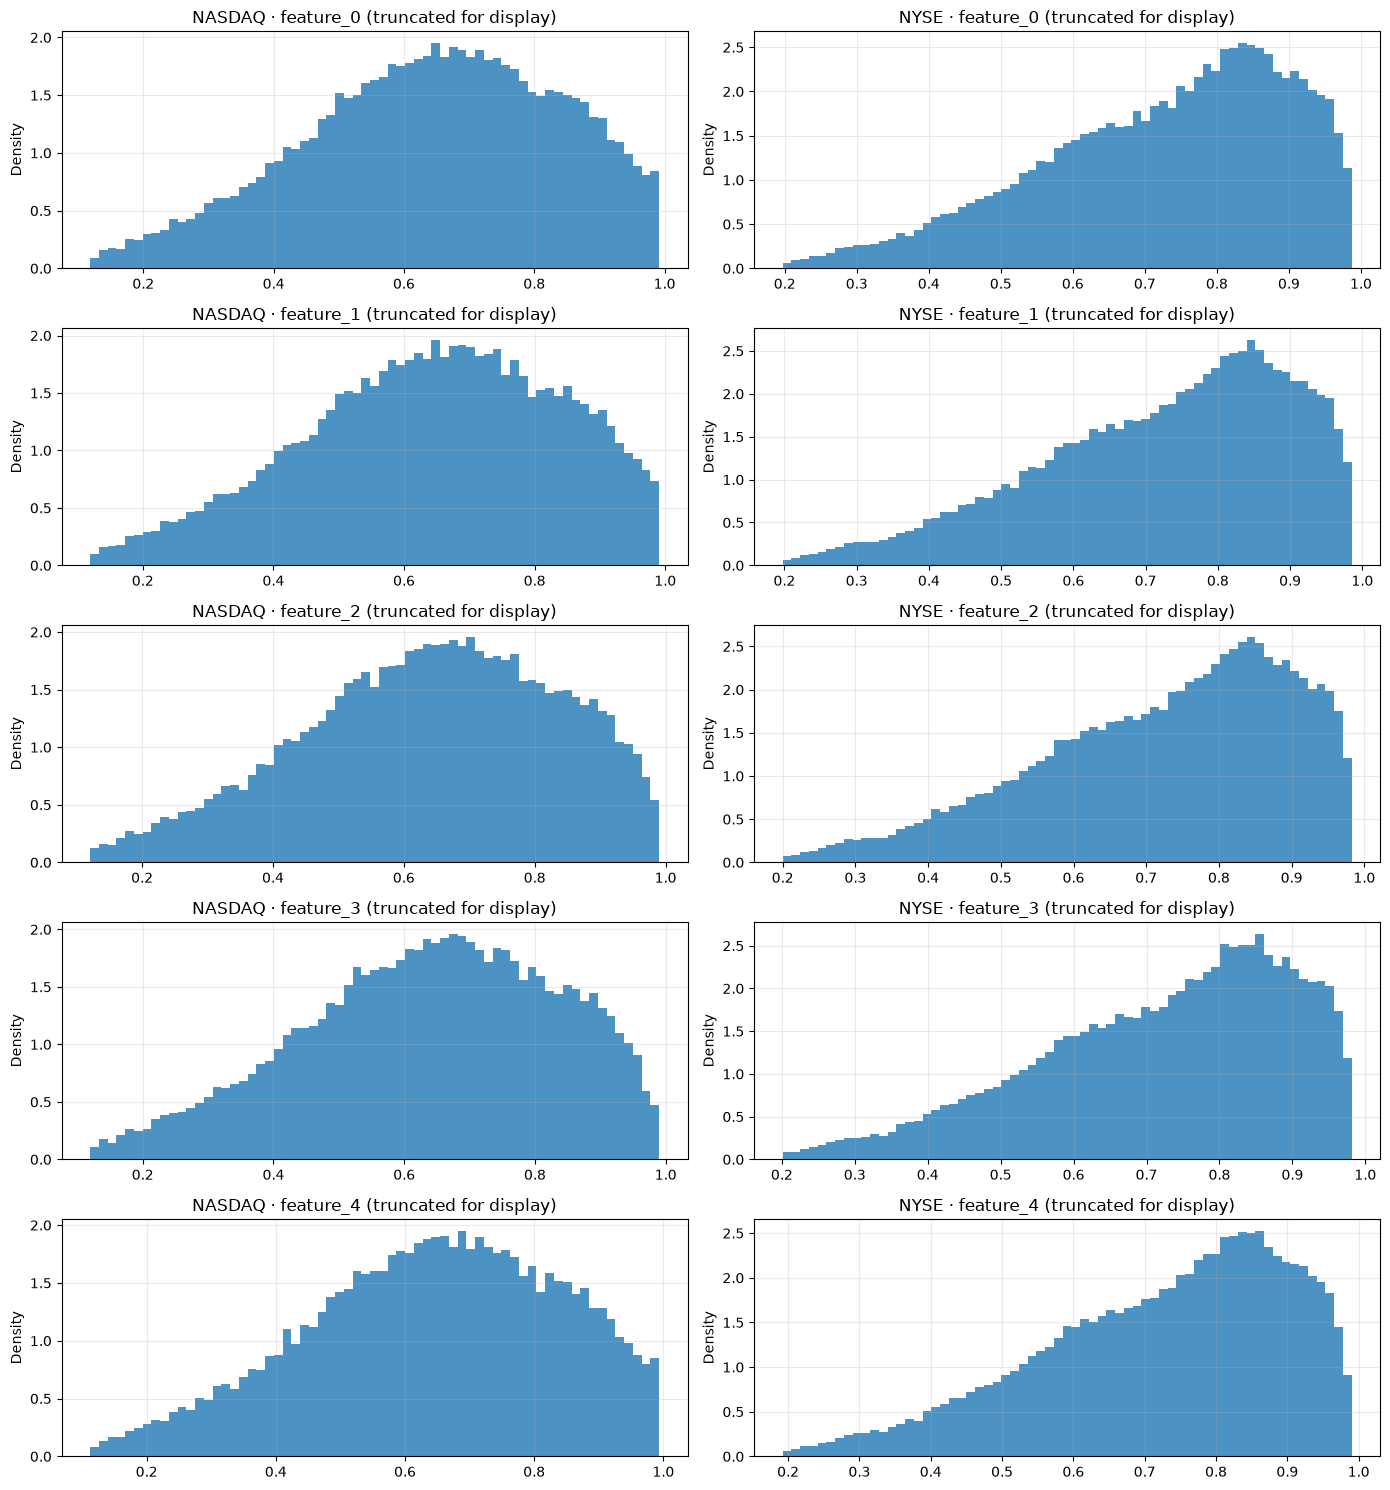

C:\Users\Bondy\AppData\Local\Temp\ipykernel_18884\2999902359.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig(dest, bbox_inches='tight', dpi=170)


D:\NCKH\PTDLKD\.venv312\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


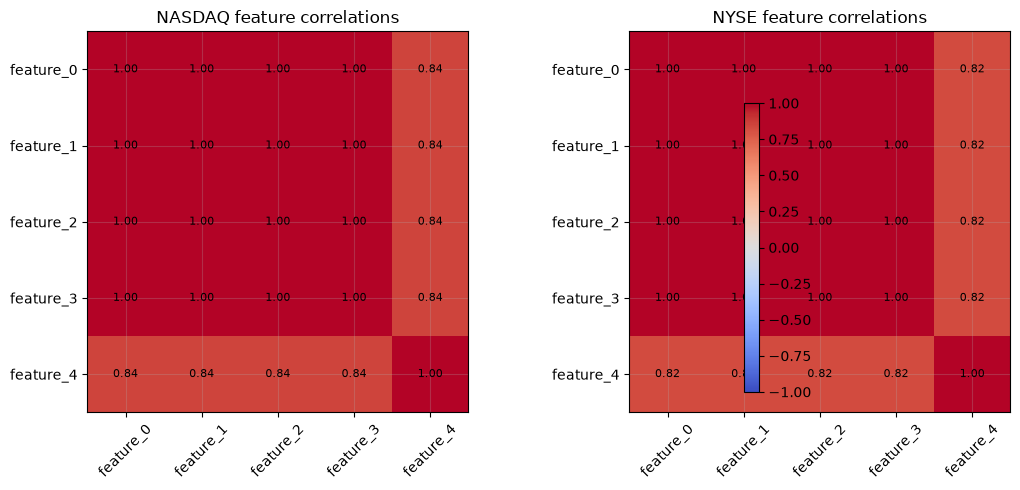

In [6]:
feature_cols=sorted([c for c in all_samples.columns if c.startswith('feature_')],
                    key=lambda v:int(v.split('_')[-1]))
features_summary=[]
for market,s in SAMPLES.items():
    for c in feature_cols:
        if c not in s:continue
        x=pd.to_numeric(s[c],errors='coerce')
        features_summary.append({'dataset':market,'feature':c,'n_sample':len(x),
             'missing_pct':100*x.isna().mean(),'zero_pct':100*(x==0).mean(),
             'mean':x.mean(),'median':x.median(),'std':x.std(),
             'q01':x.quantile(.01),'q99':x.quantile(.99)})
feat_stats=pd.DataFrame(features_summary)
display(feat_stats.round(5))
report('03_feature_distributions',feat_stats)
if feature_cols:
    fig,axs=plt.subplots(len(feature_cols),2,figsize=(14,3.0*len(feature_cols)),squeeze=False)
    for j,col in enumerate(feature_cols):
        for k,market in enumerate(('NASDAQ','NYSE')):
            s=SAMPLES[market][col].dropna().to_numpy(dtype=float)
            s=s[np.isfinite(s)]
            # Cắt HIỂN THỊ ở q0.5..99.5, thống kê gốc không cắt.
            if len(s):
                lo,hi=np.quantile(s,[.005,.995]); s=s[(s>=lo)&(s<=hi)]
                axs[j,k].hist(s,bins=65,density=True,alpha=.80)
            axs[j,k].set(title=f'{market} · {col} (truncated for display)',ylabel='Density')
    savefig('02_feature_histograms')
    fig,ax=plt.subplots(1,2,figsize=(13,5))
    for a,m in zip(ax,['NASDAQ','NYSE']):
        corr=SAMPLES[m][feature_cols].corr()
        im=a.imshow(corr,origin='upper',cmap='coolwarm',vmin=-1,vmax=1)
        a.set(xticks=np.arange(len(feature_cols)),yticks=np.arange(len(feature_cols)),
              xticklabels=feature_cols,yticklabels=feature_cols,title=f'{m} feature correlations')
        a.tick_params(axis='x',rotation=45)
        for i in range(len(feature_cols)):
            for j in range(len(feature_cols)):
                if pd.notna(corr.iloc[i,j]):
                    a.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
    fig.colorbar(im,ax=ax.ravel().tolist(),shrink=.75)
    savefig('03_feature_correlations')

## 7. Return, rủi ro, biến động, outlier NASDAQ / NYSE

Các metrics được tính cho **tất cả stock**, gồm phân phối return 1 bước, % tăng/giảm, volatility, autocorrelation, max drawdown. Các bảng **top/bottom** chỉ phản ánh chuỗi proxy và không có ý nghĩa là gợi ý đầu tư.

,dataset,stocks,mean_daily_ret_avg,median_daily_vol,median_positive_days,median_max_drawdown,median_outlier_fraction,median_lag1_autocorr,median_cumulative_change
0,NASDAQ,1026,0.00065,0.01808,0.50985,-0.38948,0.0,-0.02232,0.79547
1,NYSE,1737,0.00032,0.01423,0.50804,-0.36001,0.0,-0.00077,0.19944


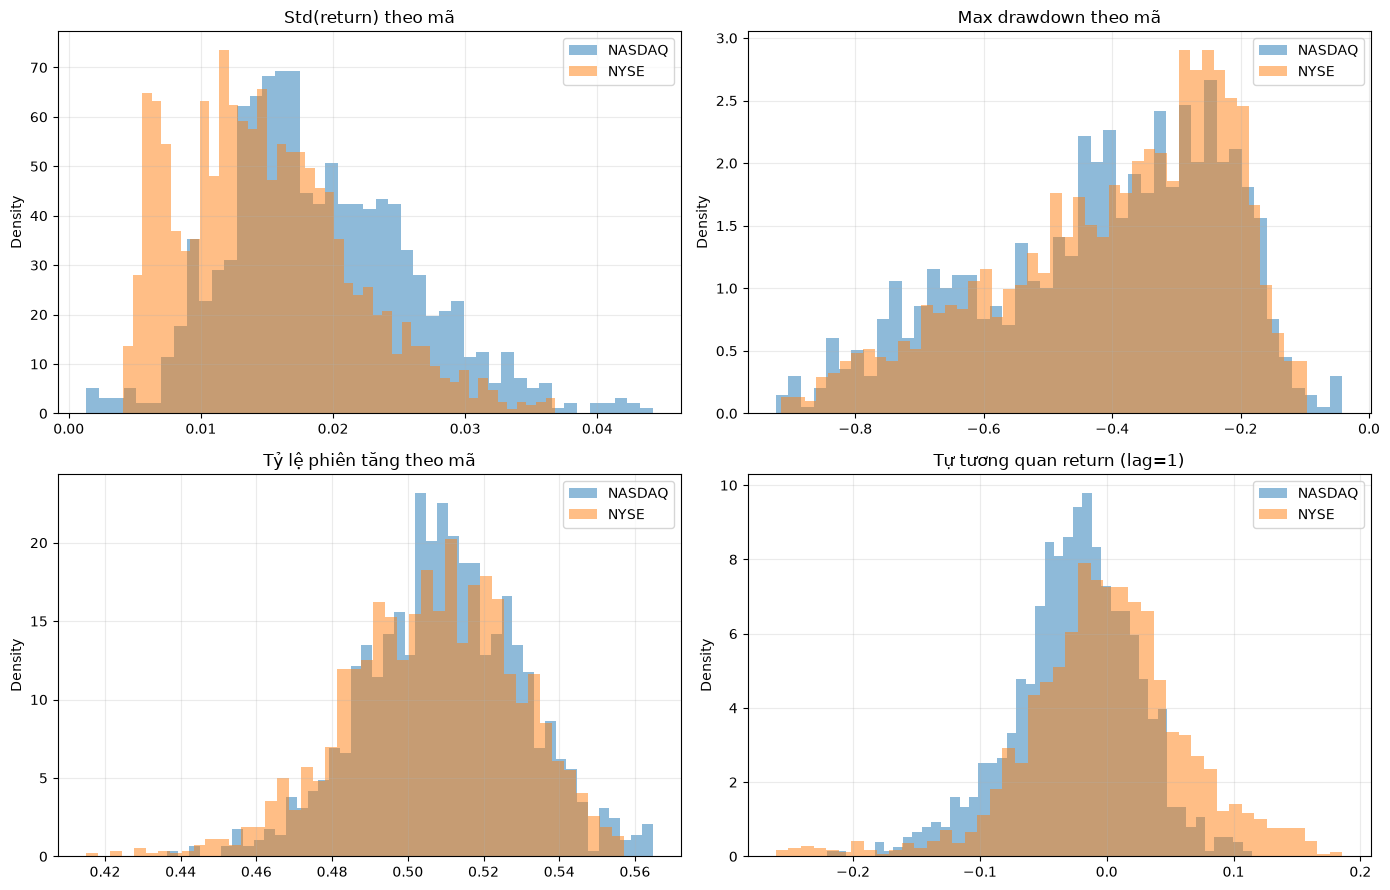

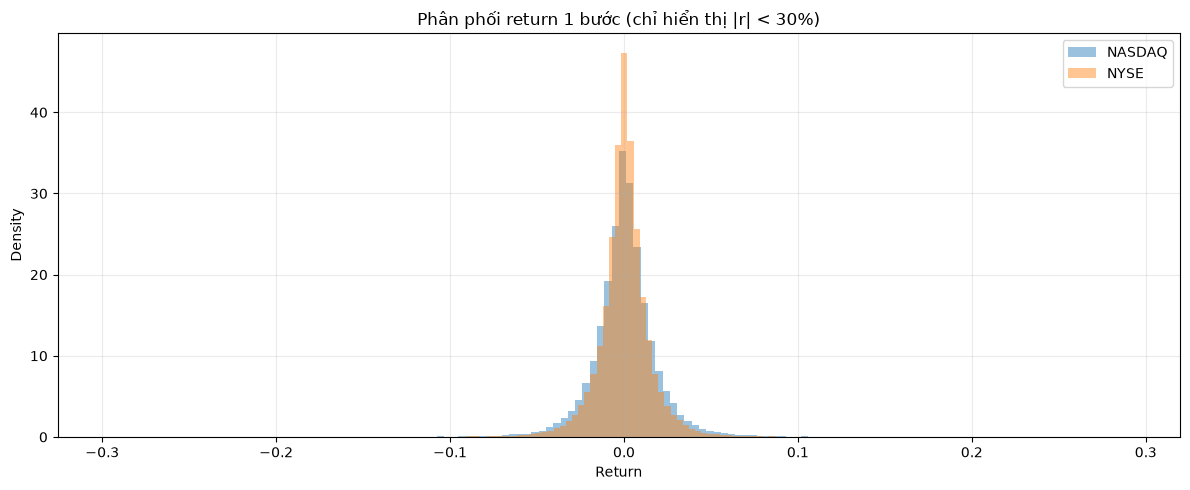

### NASDAQ: rủi ro & cực trị

,ticker,max_drawdown,daily_return_std,whole_period_proxy_change,outlier_20pct_rate
863,SQQQ,-0.964603,0.026954,-0.963188,0.000000
342,FOSL,-0.957693,0.030771,-0.926839,0.004019
353,FTR,-0.948852,0.028355,-0.850918,0.000804
106,BIS,-0.936371,0.031355,-0.927937,0.000000
80,ASPS,-0.926670,0.046189,-0.703624,0.008039
364,GEOS,-0.924242,0.036020,-0.838267,0.000804
547,MACK,-0.923702,0.044176,-0.830819,0.004819
200,CONN,-0.916456,0.044743,0.094315,0.005627
77,ASCMA,-0.909718,0.032230,-0.827882,0.004823
74,ARNA,-0.893617,0.042418,-0.646837,0.001608


### NYSE: rủi ro & cực trị

,ticker,max_drawdown,daily_return_std,whole_period_proxy_change,outlier_20pct_rate
1150,NRP,-0.971322,0.041445,-0.871695,0.004823
1691,WLL,-0.961904,0.044576,-0.860302,0.002412
388,CRR,-0.960940,0.043213,-0.875690,0.004823
1456,SRF,-0.947306,0.019550,-0.910163,0.000000
321,CHK-D,-0.944859,0.033489,-0.373413,0.006431
433,DDD,-0.933416,0.036032,-0.743749,0.002412
248,BRS,-0.922444,0.037945,-0.739218,0.004019
1429,SM,-0.917373,0.041427,-0.600586,0.004823
682,GNC,-0.915951,0.032267,-0.840158,0.004019
493,EC,-0.915361,0.023751,-0.804218,0.000000


In [7]:
risk_summary=all_stocks.groupby('dataset').agg(
    stocks=('ticker','size'),
    mean_daily_ret_avg=('daily_return_mean','mean'),
    median_daily_vol=('daily_return_std','median'),
    median_positive_days=('positive_return_rate','median'),
    median_max_drawdown=('max_drawdown','median'),
    median_outlier_fraction=('outlier_20pct_rate','median'),
    median_lag1_autocorr=('return_autocorr_lag1','median'),
    median_cumulative_change=('whole_period_proxy_change','median')).reset_index()
display(risk_summary.round(5))
report('04_risk_summary',risk_summary)
fig,axs=plt.subplots(2,2,figsize=(14,9))
metrics=[('daily_return_std','Std(return) theo mã'),
         ('max_drawdown','Max drawdown theo mã'),
         ('positive_return_rate','Tỷ lệ phiên tăng theo mã'),
         ('return_autocorr_lag1','Tự tương quan return (lag=1)')]
for ax,(col,title) in zip(axs.flat,metrics):
    for m,g in all_stocks.groupby('dataset'):
        v=g[col].to_numpy(dtype=float);v=v[np.isfinite(v)]
        if len(v):
            lo,hi=np.quantile(v,[.005,.995]); v=v[(v>=lo)&(v<=hi)]
            ax.hist(v,bins=45,density=True,alpha=.50,label=m)
    ax.set(title=title,ylabel='Density');ax.legend()
savefig('04_risk_metrics_distributions')
fig,ax=plt.subplots(figsize=(12,5))
for m,s in SAMPLES.items():
    vals=s['return_1d'].to_numpy(float);vals=vals[np.isfinite(vals)]
    if len(vals):
        vals=vals[np.abs(vals)<.30]
        ax.hist(vals,bins=140,density=True,alpha=.45,label=m)
ax.set(title='Phân phối return 1 bước (chỉ hiển thị |r| < 30%)',xlabel='Return',ylabel='Density')
ax.legend();savefig('05_returns_histogram')
for m in ('NASDAQ','NYSE'):
    t=MARKET_STATS[m]
    display(Markdown(f'### {m}: rủi ro & cực trị'))
    display(t.nsmallest(12,'max_drawdown')[['ticker','max_drawdown','daily_return_std',
                             'whole_period_proxy_change','outlier_20pct_rate']])
    report(f'05_{m.lower()}_high_volatility',t.sort_values('daily_return_std',ascending=False).head(100))
    report(f'05_{m.lower()}_drawdown',t.sort_values('max_drawdown').head(100))

## 8. Hành vi theo thời gian: index ≠ ngày lịch

Từng thị trường: coverage theo bước, tỷ lệ stock tăng qua 1 bước, return trung bình ngang thị trường, dispersion (độ phân tán), ví dụ đường giá của 6 mã. Đường chỉ **rebasing P/P_đầu** để dễ nhìn; không phải giá gốc USD.

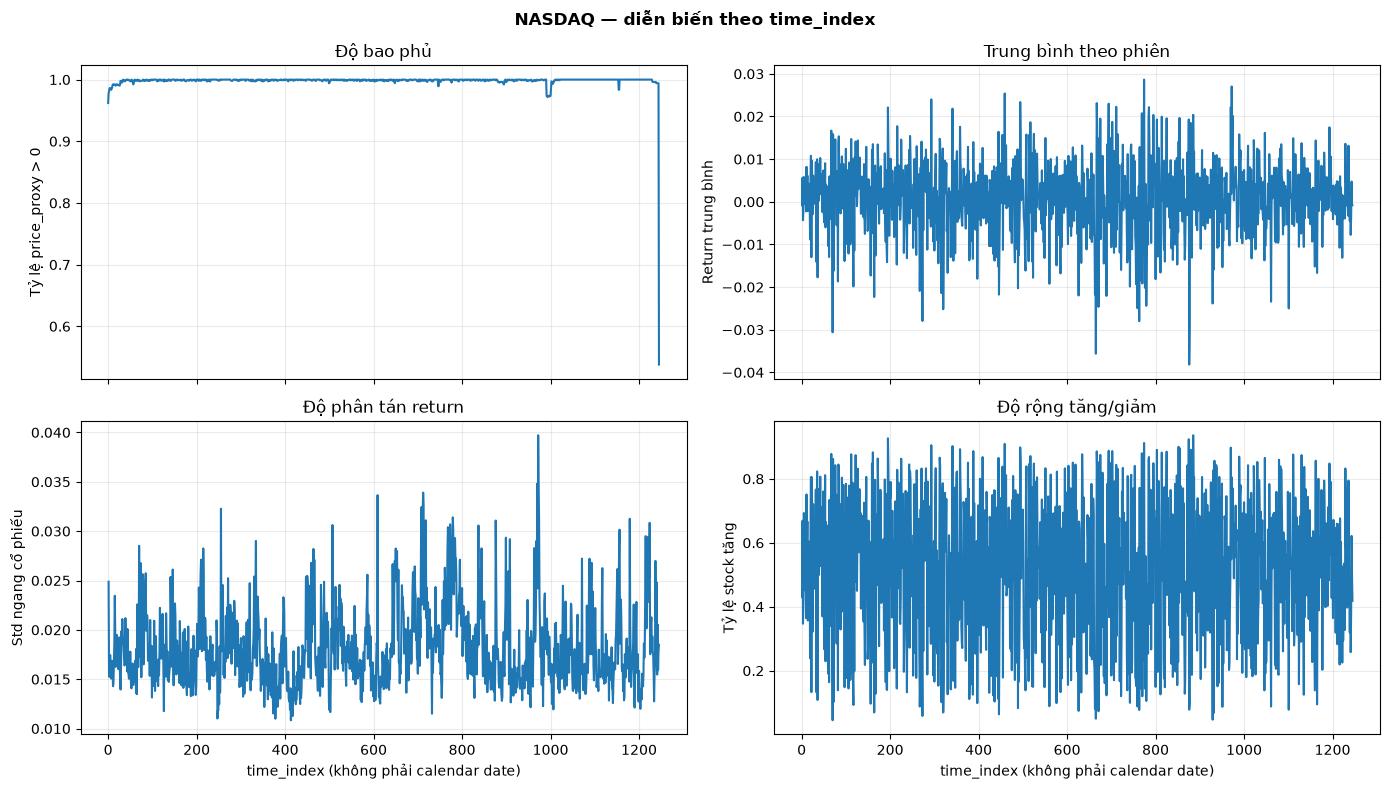

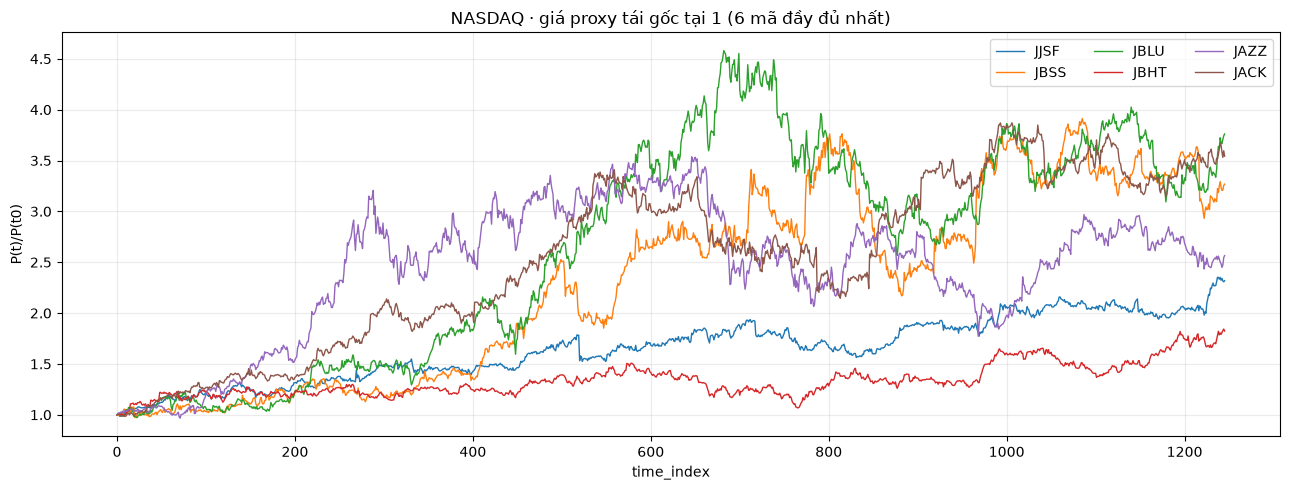

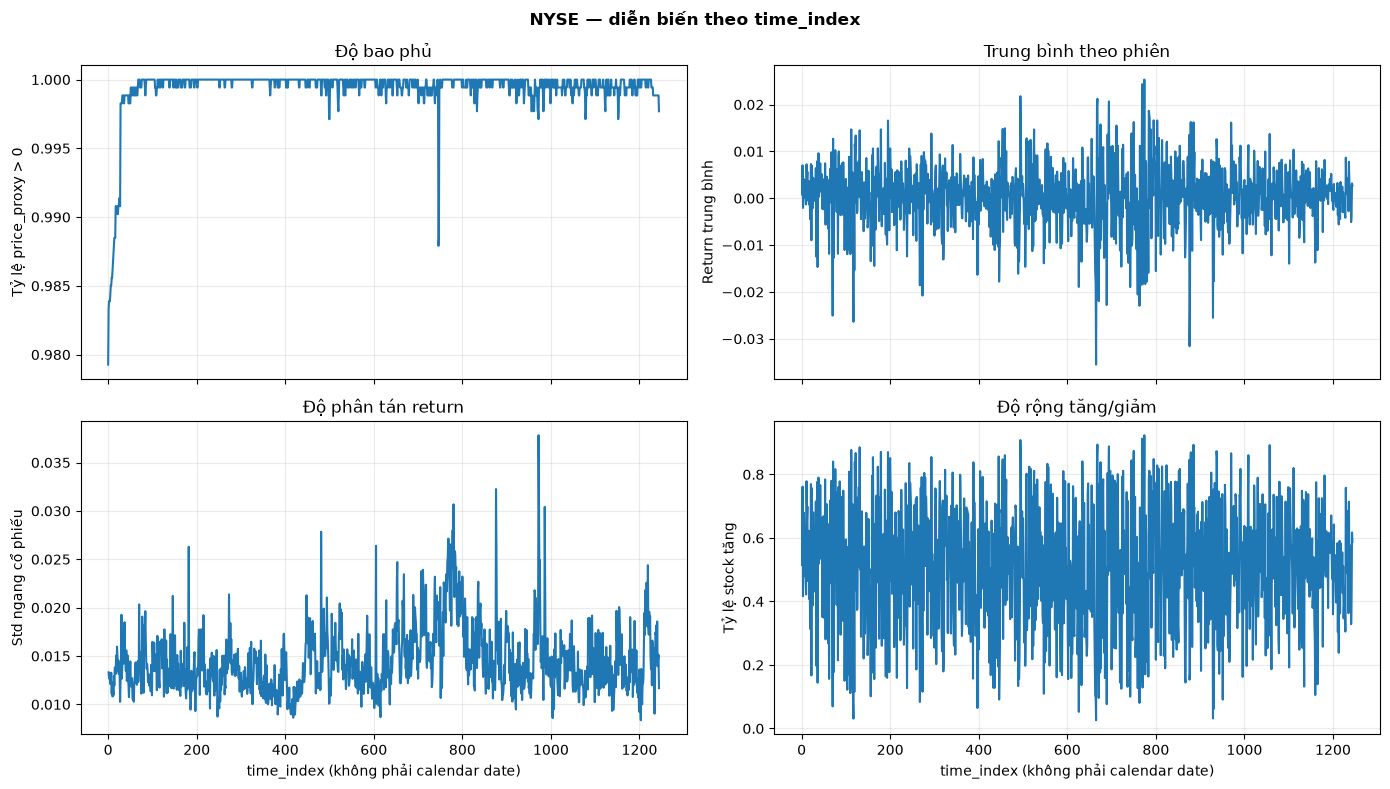

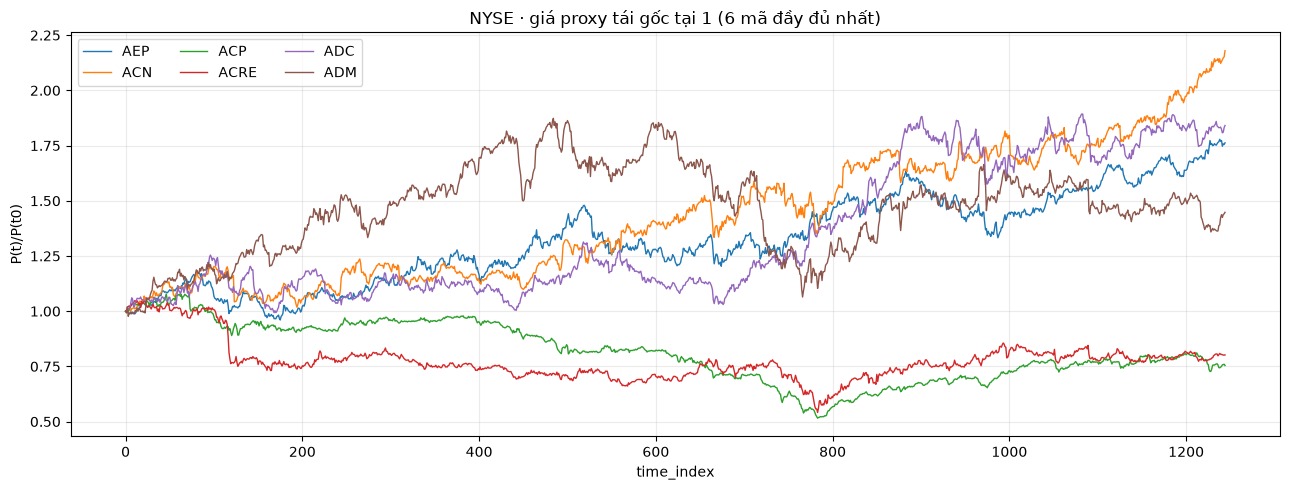

In [8]:
def timeseries_eda(market):
    obj=MATRICES[market]
    day,price,retn,names=obj['day'],obj['price'],obj['returns'],obj['tickers']
    with warnings.catch_warnings():
        warnings.simplefilter('ignore',RuntimeWarning)
        valid=np.isfinite(price)&(price>0)
        coverage=valid.mean(axis=0)
        avgret=np.nanmean(retn,axis=0)
        dispersion=np.nanstd(retn,axis=0)
        up=np.nanmean(np.where(np.isfinite(retn),retn>0,np.nan),axis=0)
    daystats=pd.DataFrame({'dataset':market,'time_index':day,'coverage':coverage,
                           'cross_section_return_mean':avgret,
                           'cross_section_return_std':dispersion,
                           'cross_section_positive_fraction':up})
    report(f'06_{market.lower()}_time_axis',daystats)
    fig,ax=plt.subplots(2,2,figsize=(14,8),sharex=True)
    ax[0,0].plot(day,coverage);ax[0,0].set(ylabel='Tỷ lệ price_proxy > 0',title='Độ bao phủ')
    ax[0,1].plot(day,avgret);ax[0,1].set(ylabel='Return trung bình',title='Trung bình theo phiên')
    ax[1,0].plot(day,dispersion);ax[1,0].set(ylabel='Std ngang cổ phiếu',title='Độ phân tán return')
    ax[1,1].plot(day,up);ax[1,1].set(ylabel='Tỷ lệ stock tăng',title='Độ rộng tăng/giảm')
    for a in ax[-1]:a.set_xlabel('time_index (không phải calendar date)')
    fig.suptitle(f'{market} — diễn biến theo time_index',fontweight='bold')
    savefig(f'06_{market.lower()}_market_dynamics')
    # 6 mã với nhiều phiên hợp lệ; thứ tự cố định để tái lập.
    candidates=np.argsort(-valid.sum(axis=1))[:min(6,len(names))]
    fig,ax=plt.subplots(figsize=(13,5))
    for idx in candidates:
        p=price[idx].astype(float);g=np.flatnonzero(np.isfinite(p)&(p>0))
        if len(g):ax.plot(day,p/p[g[0]],label=names[idx],lw=1)
    ax.set(title=f'{market} · giá proxy tái gốc tại 1 (6 mã đầy đủ nhất)',
           xlabel='time_index',ylabel='P(t)/P(t0)');ax.legend(ncol=3)
    savefig(f'07_{market.lower()}_example_stocks')
    return daystats

time_tables={m:timeseries_eda(m) for m in ('NASDAQ','NYSE') if m in MATRICES}

## 8.1. Heatmap coverage & rolling volatility (NASDAQ / NYSE)

**Heatmap:** mỗi hàng là 1 ticker, mỗi cột là một `time_index`, màu sáng = `price_proxy` hữu hạn và dương. **Rolling volatility:** tính std của return trong 30 bước. Tính trên giá hợp lệ liên tiếp, không nối xuyên qua missing.

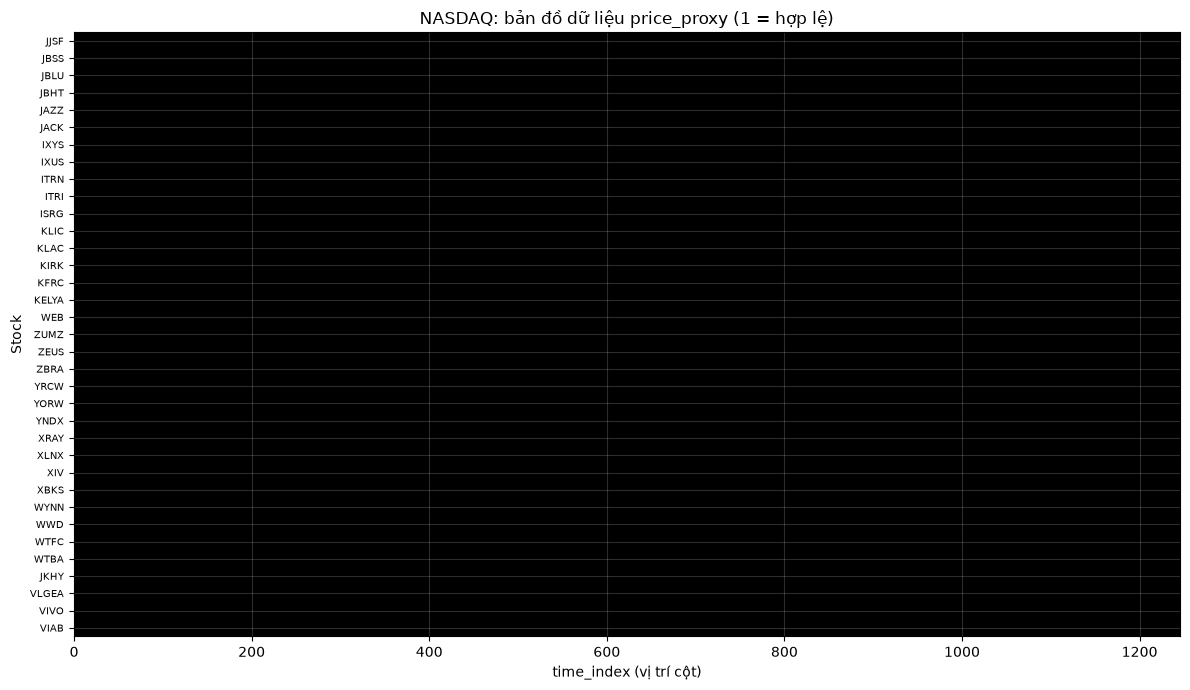

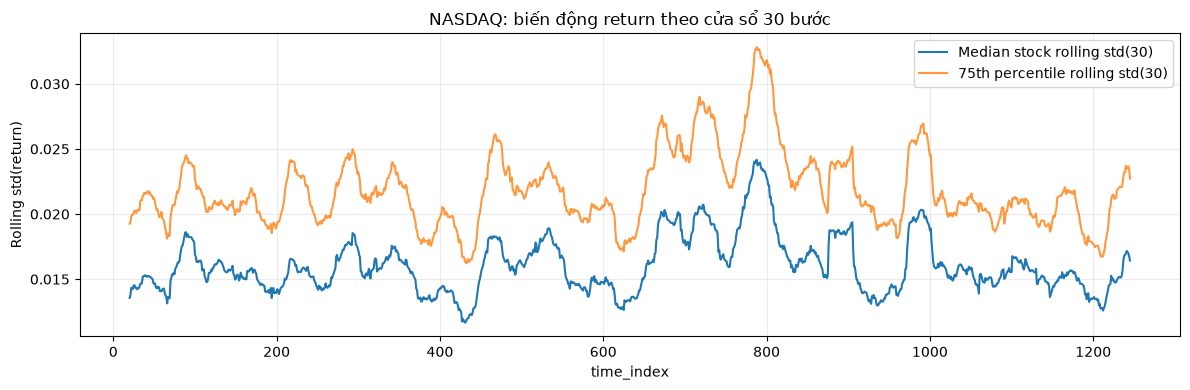

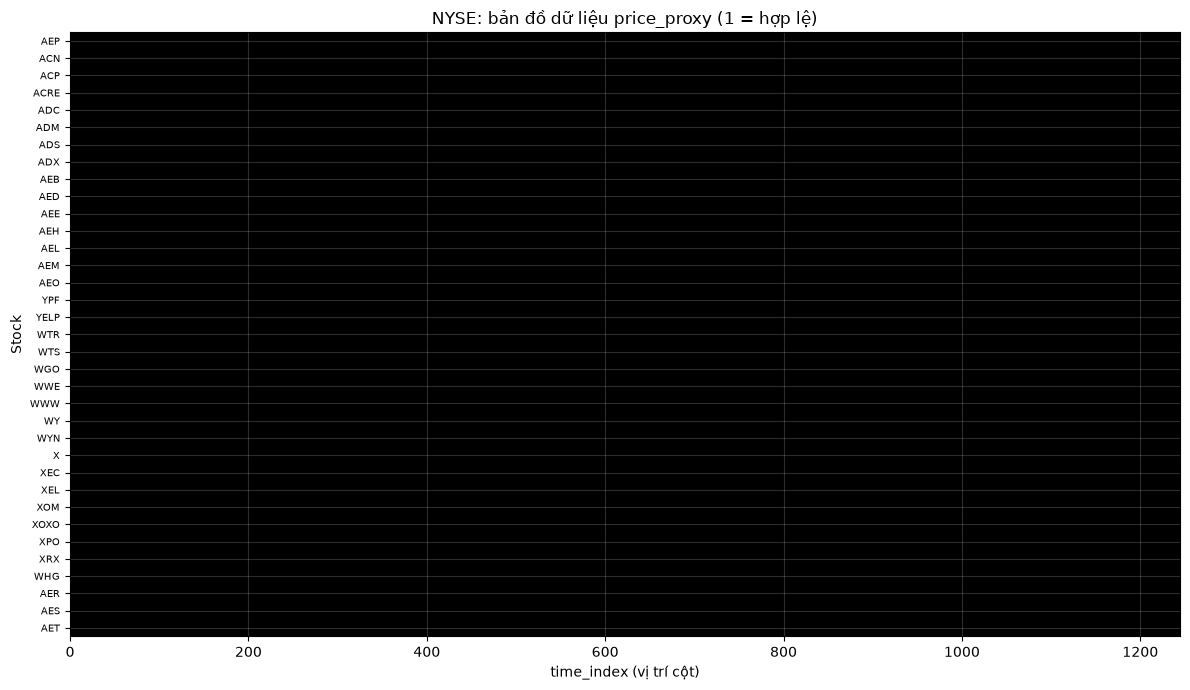

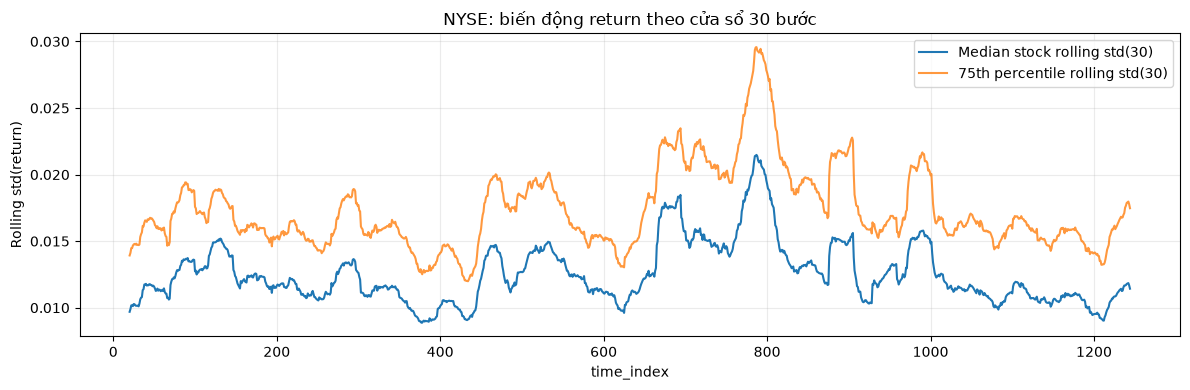

In [9]:
for market,ob in list(MATRICES.items()):
    p=ob['price']
    n=min(MAX_HEATMAP_STOCKS,p.shape[0])
    if not n:continue
    # Chọn n cổ phiếu có nhiều dữ liệu nhất để kiểm tra coverage ở phạm vi đại diện.
    valid=np.isfinite(p)&(p>0)
    ids=np.argsort(-valid.sum(axis=1))[:n]
    fig,ax=plt.subplots(figsize=(12,max(3,0.20*n)))
    ax.imshow(valid[ids].astype(int),aspect='auto',interpolation='nearest',cmap='Greys',vmin=0,vmax=1)
    ax.set(title=f'{market}: bản đồ dữ liệu price_proxy (1 = hợp lệ)',
           xlabel='time_index (vị trí cột)',ylabel='Stock')
    ax.set_yticks(range(n));ax.set_yticklabels([ob['tickers'][i] for i in ids],fontsize=7)
    savefig(f'07b_{market.lower()}_coverage_heatmap')
    rolling=pd.DataFrame(ob['returns'].T).rolling(window=30,min_periods=20).std()
    med=rolling.median(axis=1,skipna=True)
    q75=rolling.quantile(.75,axis=1)
    fig,ax=plt.subplots(figsize=(12,4))
    ax.plot(ob['day'],med,label='Median stock rolling std(30)')
    ax.plot(ob['day'],q75,label='75th percentile rolling std(30)',alpha=.8)
    ax.set(title=f'{market}: biến động return theo cửa sổ 30 bước',
           xlabel='time_index',ylabel='Rolling std(return)');ax.legend()
    savefig(f'07c_{market.lower()}_rolling_volatility')

## 9. Chẩn đoán S&P 500: tensor, kích thước, feature, ticker metadata

**Ưu tiên `SP500.npy`** (đúng định dạng StockMixer). Nếu thiếu `.npy`, đọc `SP500.csv` được xuất từ cùng tensor. Nếu số dòng ticker list không bằng số cổ phiếu tensor, **không tự ghép ticker theo thứ tự** (sai nhãn rất nguy hiểm).

In [10]:
spdir=DATA_ROOT/'SP500'
sp_npy=spdir/'SP500.npy'
sp_csv=spdir/'SP500.csv'
meta_path=spdir/'sp500_ticker.csv'
META = pd.read_csv(meta_path,encoding='utf-8-sig') if meta_path.exists() else pd.DataFrame()
if not META.empty:
    META.columns=[str(c).strip() for c in META.columns]
    if 'Symbol' in META: META['Symbol']=META['Symbol'].astype(str).str.strip()
    display(META.head(8))
    print('Metadata ticker count:',len(META),'| columns:',list(META.columns))
    report('07_sp500_metadata',META)
SP_NPY=None
SP_SHAPE=None
if sp_npy.exists():
    # Memory-map không cần load cả tensor, không cho unpickle.
    SP_NPY=np.load(sp_npy,mmap_mode='r',allow_pickle=False)
    if SP_NPY.ndim==2:
        SP_NPY=SP_NPY[:,:,None]
    if SP_NPY.ndim != 3:
        raise ValueError(f'SP500.npy phải là tensor 2D/3D, hiện là {SP_NPY.shape}')
    SP_SHAPE=SP_NPY.shape
    print('Nguồn SP500: SP500.npy | shape (stock,time,feature) =',SP_SHAPE,'| dtype=',SP_NPY.dtype)
elif sp_csv.exists():
    header=pd.read_csv(sp_csv,nrows=4)
    print('Không thấy SP500.npy, dùng CSV xuất từ tensor:',list(header.columns))
else:
    warnings.warn('Không có SP500.npy hoặc SP500.csv, chỉ phân tích baseline nếu có.')
if SP_SHAPE:
    if not META.empty and len(META)!=SP_SHAPE[0]:
        print('CẢNH BÁO: số ticker metadata khác số stock tensor => giữ stock_index, KHÔNG tự suy ra tên mã.')
    else:
        print('LƯU Ý: khớp số lượng không tự chứng minh khớp thứ tự ticker; giữ stock_index.')

,Symbol,Name,Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ABMD,Abiomed,Health Care
5,ACN,Accenture,Information Technology
6,ATVI,Activision Blizzard,Communication Services
7,ADM,ADM,Consumer Staples


Metadata ticker count: 505 | columns: ['Symbol', 'Name', 'Sector']
Nguồn SP500: SP500.npy | shape (stock,time,feature) = (474, 2526, 5) | dtype= float64
CẢNH BÁO: số ticker metadata khác số stock tensor => giữ stock_index, KHÔNG tự suy ra tên mã.


## 10. Quét toàn bộ tensor S&P 500 và tổng hợp EDA tương đương

Đọc theo từng stock; không giải mã đặc trưng khi không có tài liệu ánh xạ. CSV xuất từ script chứa `stock_index`, `time_index`, `feature_0...`. Với tensor sử dụng kênh cuối làm price_proxy theo cách tính target của code StockMixer.

SP500: 200 mã đã quét


SP500: 400 mã đã quét


SP500 đã đọc: 474 stocks


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
dataset,474,1,SP500,474,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ticker,474,474,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rows,474.0,NaN,NaN,NaN,2526.0,0.0,2526.0,2526.0,2526.0,2526.0,2526.0
n_features,474.0,NaN,NaN,NaN,5.0,0.0,5.0,5.0,5.0,5.0,5.0
time_first,474.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
time_last,474.0,NaN,NaN,NaN,2525.0,0.0,2525.0,2525.0,2525.0,2525.0,2525.0
duplicate_time_index,474.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
time_not_monotonic,474.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
missing_feature_cells,474.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
missing_fraction,474.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0


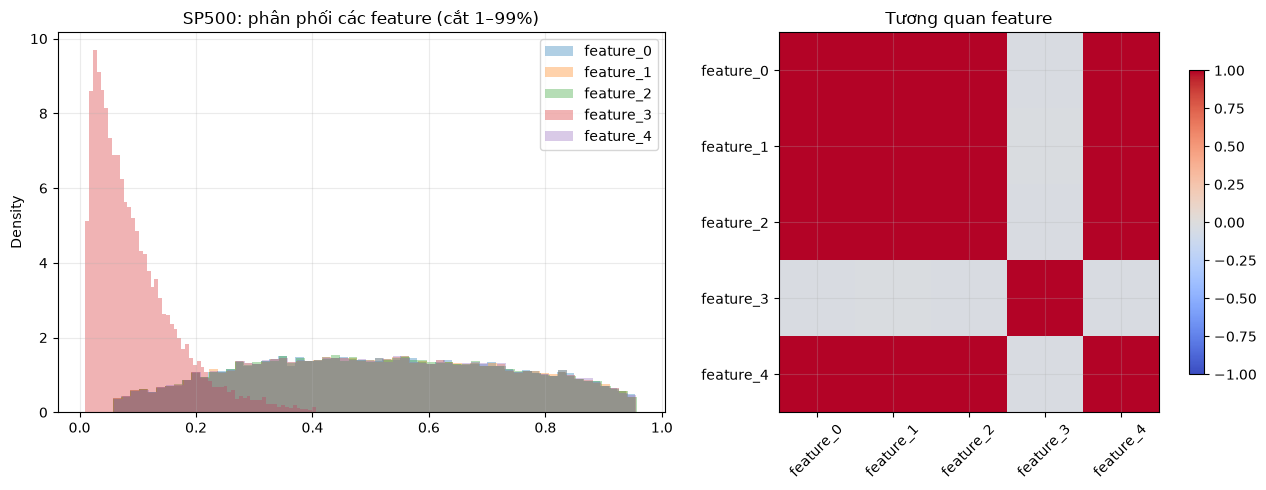

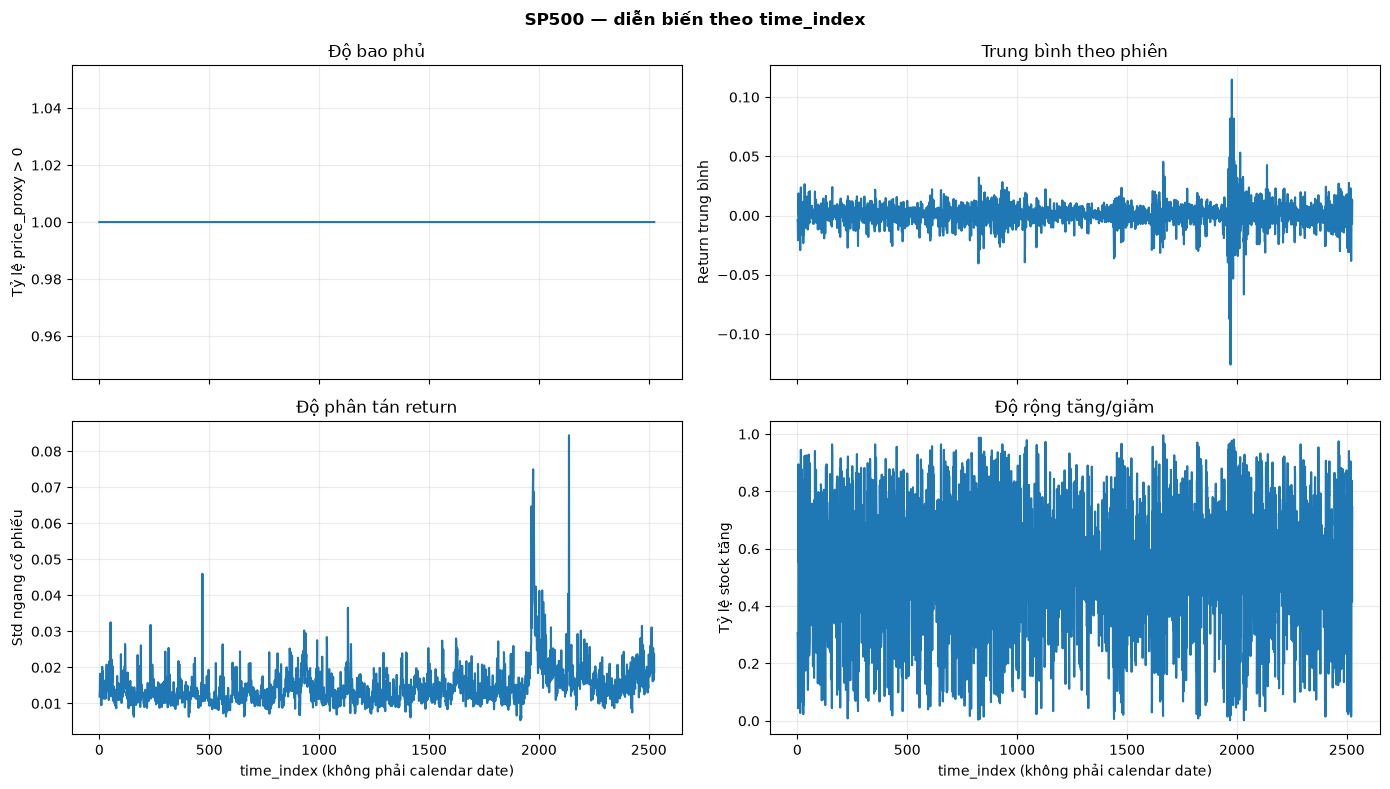

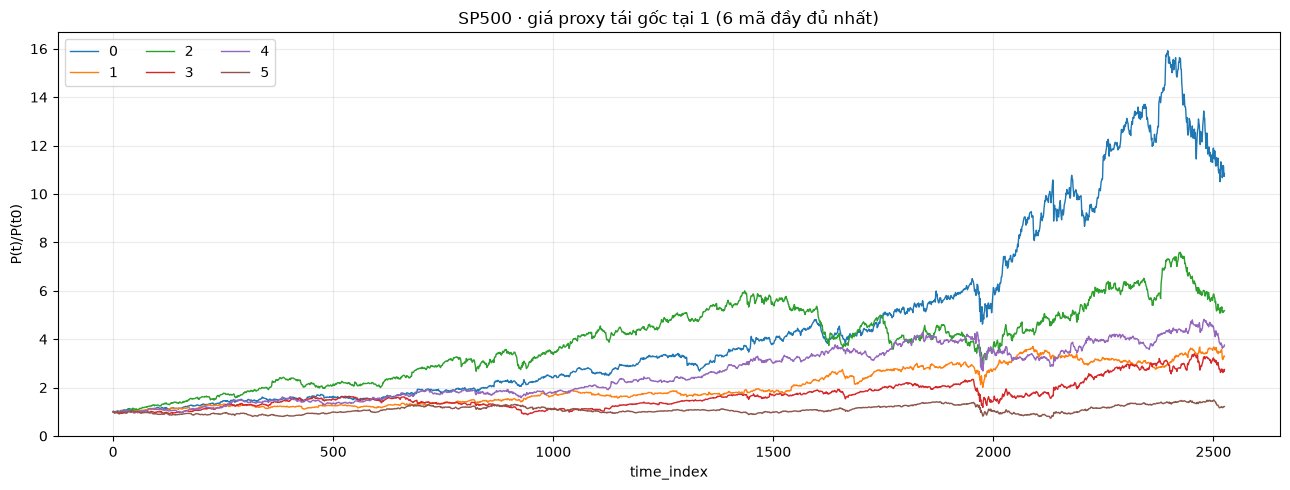

In [11]:
def iter_sp500_stocks():
    if SP_NPY is not None:
        n,t,f=SP_NPY.shape
        for i in range(n):
            yield str(i), np.arange(t,dtype=float), np.asarray(SP_NPY[i],dtype=float)
    elif sp_csv.exists():
        # Xuất CSV theo stock_index liên tiếp. Chunks để không đọc hết file lớn vào RAM.
        carry=pd.DataFrame()
        for chunk in pd.read_csv(sp_csv,chunksize=150000):
            chunk=pd.concat([carry,chunk],ignore_index=True) if not carry.empty else chunk
            if 'stock_index' not in chunk.columns:
                raise ValueError('SP500.csv cần có cột stock_index')
            last_index=chunk['stock_index'].iloc[-1]
            done=chunk[chunk['stock_index']!=last_index]
            carry=chunk[chunk['stock_index']==last_index]
            for idx,g in done.groupby('stock_index',sort=False):
                fc=sorted([c for c in g.columns if c.startswith('feature_')],
                          key=lambda c:int(c.split('_')[-1]))
                yield str(idx),pd.to_numeric(g['time_index'],errors='coerce').to_numpy(float),g[fc].to_numpy(float)
        if len(carry):
            fc=sorted([c for c in carry.columns if c.startswith('feature_')],
                      key=lambda c:int(c.split('_')[-1]))
            yield str(carry['stock_index'].iloc[0]),carry['time_index'].to_numpy(float),carry[fc].to_numpy(float)

sp_stats=[];sp_sam=[];sp_series=[];sp_names=[];sp_bad=[]
for i,(stock,days,features) in enumerate(iter_sp500_stocks(),1):
    try:
        sp_stats.append(summarize_stock('SP500',stock,days,features))
        sampled=sample_rows('SP500',stock,days,features)
        if sampled is not None:sp_sam.append(sampled)
        sp_series.append((days,features[:,-1]));sp_names.append(stock)
    except Exception as e:sp_bad.append({'stock_index':stock,'error':str(e)})
    if i%200==0:print('SP500:',i,'mã đã quét')
MARKET_STATS['SP500']=pd.DataFrame(sp_stats)
SAMPLES['SP500']=pd.concat(sp_sam,ignore_index=True) if sp_sam else pd.DataFrame()
if sp_series:
    d,m=build_matrix(sp_series)
    MATRICES['SP500']={'day':d,'price':m,'tickers':sp_names,'returns':get_matrix_returns(m)}
report('08_sp500_per_stock',MARKET_STATS['SP500'],sort_by='daily_return_std')
report('08_sp500_read_errors',pd.DataFrame(sp_bad))
print('SP500 đã đọc:',len(sp_stats),'stocks')
if not MARKET_STATS['SP500'].empty:
    display(MARKET_STATS['SP500'].describe(include='all').T.round(4))
    fig,ax=plt.subplots(1,2,figsize=(13,5))
    s=SAMPLES['SP500']
    fc=sorted([c for c in s.columns if c.startswith('feature_')],key=lambda c:int(c.split('_')[-1]))
    for c in fc:
        x=s[c].dropna().to_numpy(float);x=x[np.isfinite(x)]
        if len(x):
            lo,hi=np.quantile(x,[.01,.99]);x=x[(x>=lo)&(x<=hi)]
            ax[0].hist(x,bins=60,alpha=.35,density=True,label=c)
    ax[0].set(title='SP500: phân phối các feature (cắt 1–99%)',ylabel='Density');ax[0].legend()
    corr=s[fc].corr();im=ax[1].imshow(corr,cmap='coolwarm',vmin=-1,vmax=1)
    ax[1].set(xticks=range(len(fc)),yticks=range(len(fc)),xticklabels=fc,yticklabels=fc,
              title='Tương quan feature')
    ax[1].tick_params(axis='x',rotation=45)
    fig.colorbar(im,ax=ax[1],shrink=.8)
    savefig('08_sp500_feature_distributions_correlations')
    time_tables['SP500']=timeseries_eda('SP500')

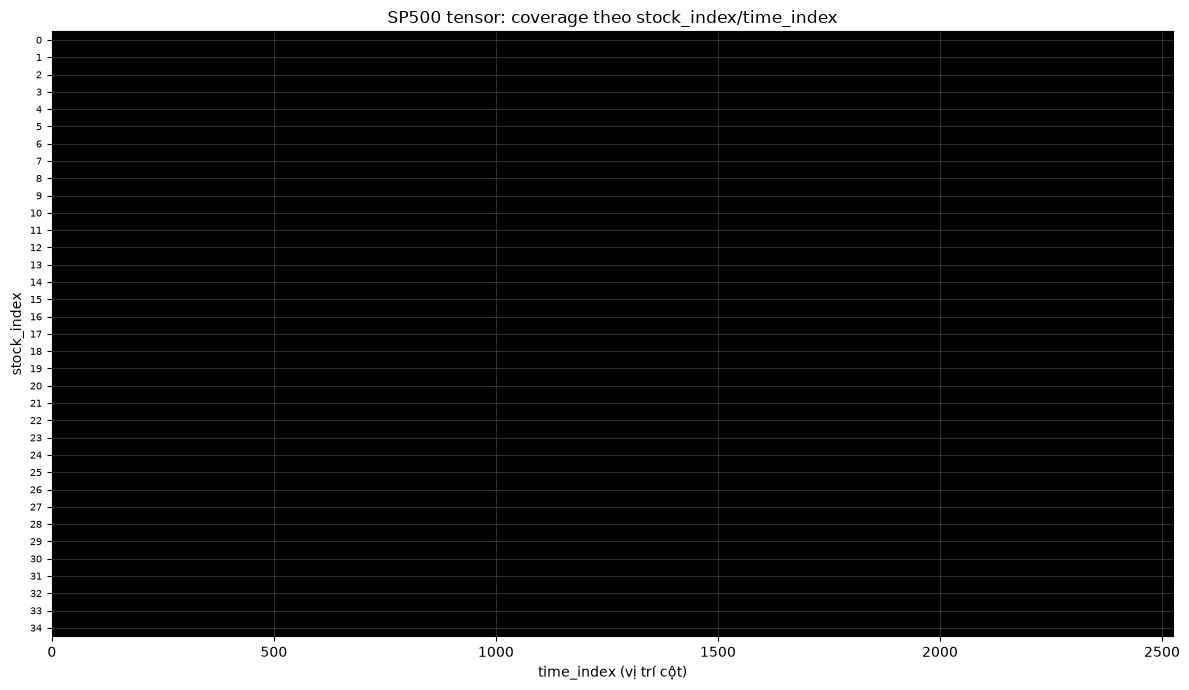

In [12]:
if 'SP500' in MATRICES:
    ob=MATRICES['SP500'];p=ob['price'];valid=np.isfinite(p)&(p>0)
    ids=np.argsort(-valid.sum(axis=1))[:min(MAX_HEATMAP_STOCKS,len(p))]
    fig,ax=plt.subplots(figsize=(12,max(3,len(ids)*.20)))
    ax.imshow(valid[ids].astype(int),aspect='auto',interpolation='nearest',cmap='Greys',vmin=0,vmax=1)
    ax.set(title='SP500 tensor: coverage theo stock_index/time_index',
           xlabel='time_index (vị trí cột)',ylabel='stock_index')
    ax.set_yticks(range(len(ids)));ax.set_yticklabels([ob['tickers'][i] for i in ids],fontsize=7)
    savefig('08b_sp500_coverage_heatmap')

## 11. S&P 500 baseline OHLCV: metadata, tính hợp lệ và biến động theo năm

`baseline_data_sp500.csv` nếu có, có thể chứa **giá thực và ngày**. Cell sẽ tự tìm cột `stock_key`/`Date`/`close`... Tập hợp báo cáo toàn bộ CSV bằng chunk; mẫu hình chỉ giới hạn 50.000 dòng. Nếu baseline không có CSV, notebook vẫn tiếp tục không unpickle file `.npy`.

Baseline columns: ['stock_key', 'index', 'close', 'open', 'high', 'low', 'volume', 'adjclose']
Nhận diện: {'stock': 'stock_key', 'date': 'index', 'close': 'adjclose', 'open': 'open', 'high': 'high', 'low': 'low', 'volume': 'volume'}
Đã đọc baseline: 100,000 dòng


Đã đọc baseline: 1,100,000 dòng


,rows,stocks,years,invalid_date,close_nonpositive,volume_negative,high_lt_low,close_outside_range
0,1197324,474,11,0,0,0,0,27295


,column,missing_count,missing_pct,dtype_sample
7,adjclose,3450,0.288,float64
0,stock_key,0,0.000,object
2,close,0,0.000,float64
1,index,0,0.000,object
3,open,0,0.000,float64
4,high,0,0.000,float64
5,low,0,0.000,float64
6,volume,0,0.000,float64


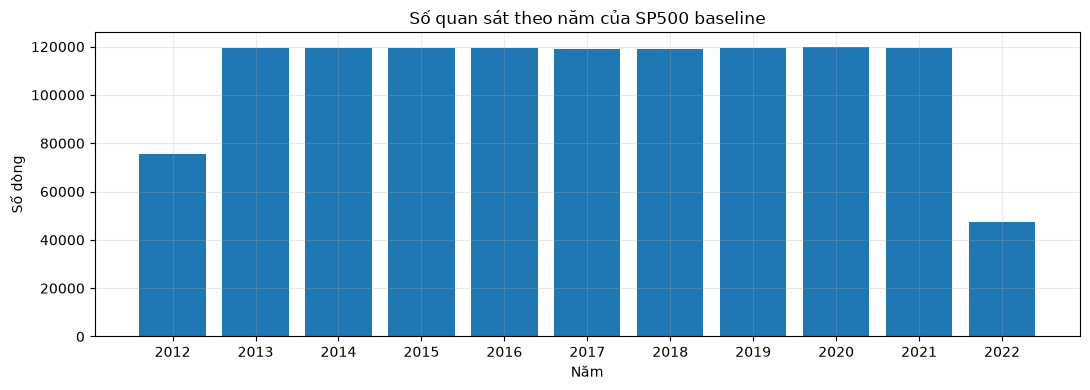

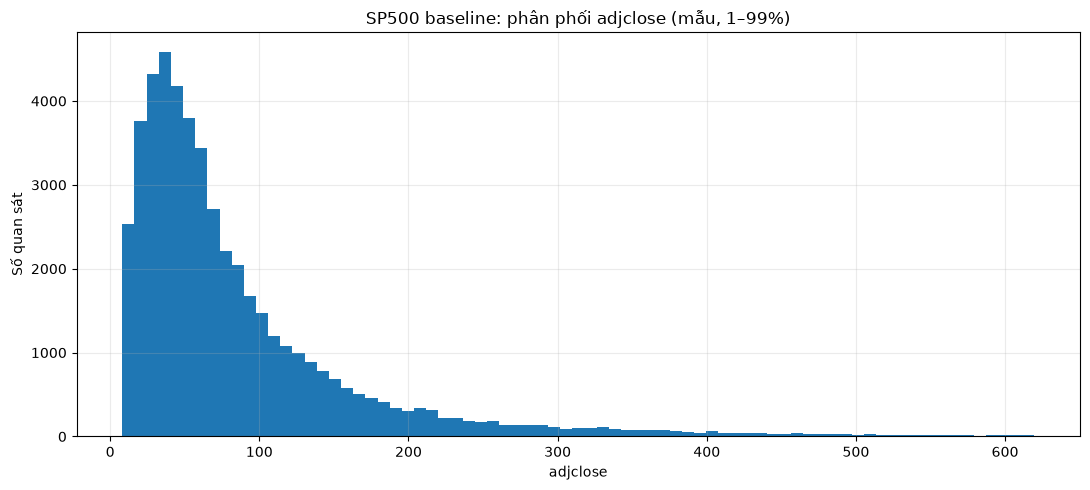

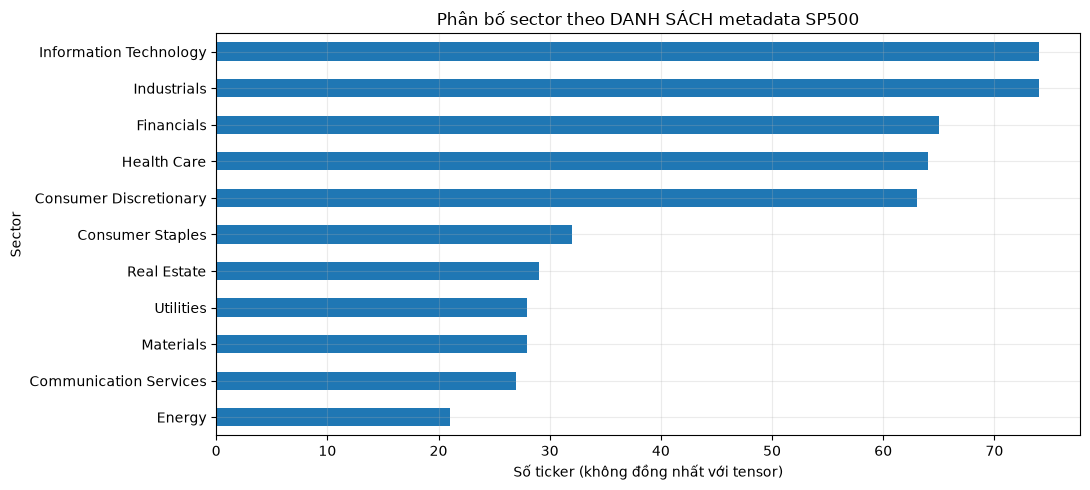

In [13]:
baseline_csv=spdir/'baseline_data_sp500.csv'
BASELINE_SAMPLE=pd.DataFrame()
BASELINE_QA=pd.DataFrame()
if baseline_csv.exists():
    header=pd.read_csv(baseline_csv,nrows=5,low_memory=False)
    columns=list(header.columns)
    print('Baseline columns:',columns)
    def match_col(candidates, cols):
        norm={re.sub(r'[^a-z0-9]','',str(c).lower()):c for c in cols}
        for c in candidates:
            if c in norm:return norm[c]
        return None
    key_col=match_col(['stockkey','ticker','symbol','stockindex'],columns)
    date_col=match_col(['date','datetime','timestamp','index','tradingdate'],columns)
    close_col=match_col(['adjclose','adjustedclose','close'],columns)
    raw_close_col=match_col(['close'],columns) # dùng close chưa điều chỉnh để kiểm tra OHLC
    open_col=match_col(['open'],columns)
    high_col=match_col(['high'],columns)
    low_col=match_col(['low'],columns)
    volume_col=match_col(['volume'],columns)
    print('Nhận diện:',{'stock':key_col,'date':date_col,'close':close_col,
                           'open':open_col,'high':high_col,'low':low_col,'volume':volume_col})
    totals=Counter(); missing=Counter(); per_stock=Counter(); per_year=Counter()
    reservoir=pd.DataFrame();total_rows=0
    for j,chunk in enumerate(pd.read_csv(baseline_csv,chunksize=100000,low_memory=False)):
        total_rows+=len(chunk)
        for c in chunk.columns:missing[c]+=int(chunk[c].isna().sum())
        if key_col:
            per_stock.update(chunk[key_col].dropna().astype(str).value_counts().to_dict())
        if date_col:
            dates=pd.to_datetime(chunk[date_col],errors='coerce')
            per_year.update(dates.dt.year.dropna().astype(int).value_counts().to_dict())
            totals['invalid_date']+=int(dates.isna().sum())
        if close_col:
            vals=pd.to_numeric(chunk[close_col],errors='coerce')
            totals['close_nonpositive']+=int((vals<=0).sum())
        if volume_col:
            vols=pd.to_numeric(chunk[volume_col],errors='coerce')
            totals['volume_negative']+=int((vols<0).sum())
        if all(c is not None for c in (low_col,high_col,raw_close_col)):
            low=pd.to_numeric(chunk[low_col],errors='coerce')
            high=pd.to_numeric(chunk[high_col],errors='coerce')
            close=pd.to_numeric(chunk[raw_close_col],errors='coerce')
            totals['high_lt_low']+=int((high<low).sum())
            totals['close_outside_range']+=int(((close<low)|(close>high)).sum())
        # Priority sampling đồng đều qua TOÀN BỘ các chunk, không chỉ chunk đầu.
        if MAX_BASELINE_SAMPLE > 0:
            temp=chunk.assign(__sample_key=RNG.random(len(chunk)))
            temp=temp.nsmallest(min(MAX_BASELINE_SAMPLE,len(temp)), '__sample_key')
            reservoir=pd.concat([reservoir,temp],ignore_index=True)
            reservoir=reservoir.nsmallest(min(MAX_BASELINE_SAMPLE,len(reservoir)), '__sample_key')
        if j%10==0:print('Đã đọc baseline:',f'{total_rows:,}', 'dòng')
    BASELINE_SAMPLE=reservoir.drop(columns='__sample_key').reset_index(drop=True) if len(reservoir) else pd.DataFrame()
    qa=[{'column':c,'missing_count':missing[c],'missing_pct':100*missing[c]/total_rows,
         'dtype_sample':str(header[c].dtype)} for c in columns]
    BASELINE_QA=pd.DataFrame(qa)
    report('09_sp500_baseline_columns_missing',BASELINE_QA,sort_by='missing_pct')
    report('09_sp500_baseline_stock_counts',pd.DataFrame(
        [{'stock_key':k,'rows':v} for k,v in per_stock.items()]),sort_by='rows')
    report('09_sp500_baseline_year_counts',pd.DataFrame(
        [{'year':k,'rows':v} for k,v in per_year.items()]),sort_by='year',ascending=True)
    display(pd.DataFrame([{'rows':total_rows,'stocks':len(per_stock),'years':len(per_year),**totals}]))
    display(BASELINE_QA.sort_values('missing_pct',ascending=False).head(20).round(3))
    if per_year:
        x=pd.Series(per_year).sort_index()
        fig,ax=plt.subplots(figsize=(11,4));ax.bar(x.index.astype(str),x.values)
        ax.set(title='Số quan sát theo năm của SP500 baseline',xlabel='Năm',ylabel='Số dòng')
        savefig('09_sp500_baseline_year_coverage')
    if close_col and not BASELINE_SAMPLE.empty:
        vals=pd.to_numeric(BASELINE_SAMPLE[close_col],errors='coerce')
        vals=vals[np.isfinite(vals)&(vals>0)]
        if len(vals):
            lo,hi=vals.quantile([.01,.99]);vals=vals[(vals>=lo)&(vals<=hi)]
            fig,ax=plt.subplots();ax.hist(vals,bins=75)
            ax.set(title=f'SP500 baseline: phân phối {close_col} (mẫu, 1–99%)',
                   xlabel=close_col,ylabel='Số quan sát');savefig('10_sp500_baseline_close')
    if 'Sector' in META.columns:
        fig,ax=plt.subplots(figsize=(11,5))
        counts=META['Sector'].fillna('Unknown').value_counts().sort_values()
        counts.plot.barh(ax=ax);ax.set(title='Phân bố sector theo DANH SÁCH metadata SP500',
                                        xlabel='Số ticker (không đồng nhất với tensor)')
        savefig('11_sp500_metadata_sectors')
else:
    print('Không có baseline_data_sp500.csv: bỏ qua đánh giá OHLCV và calendar date.')
    print('Lưu ý: KHÔNG mở .npy baseline bằng allow_pickle=True nếu chưa xác minh độ tin cậy.')

## 12. So sánh ba dataset — cùng tiêu chí tính được, khác tiền xử lý

So sánh: số cổ phiếu; chiều dài; số feature; missing; return-volatility; outlier; xu hướng lên/xuống; mức biến động giữa cổ phiếu. **Không khẳng định return có cùng bản chất tài chính** nếu 3 nguồn được normalize khác nhau.

,dataset,n_stocks,total_rows,median_steps,n_features_min,n_features_max,missing_pct,zero_pct,median_daily_return,median_daily_volatility,median_positive_rate,median_drawdown,median_outlier_rate,median_return_autocorr
0,NASDAQ,1026,1278396,1246.0,5,5,0.0,0.0,0.00062,0.01808,0.50985,-0.38948,0.0,-0.02232
1,NYSE,1737,2162565,1245.0,5,5,0.0,0.0,0.00027,0.01423,0.50804,-0.36001,0.0,-0.00077
2,SP500,474,1197324,2526.0,5,5,0.0,0.0,0.00062,0.01753,0.52317,-0.48836,0.0,-0.04645


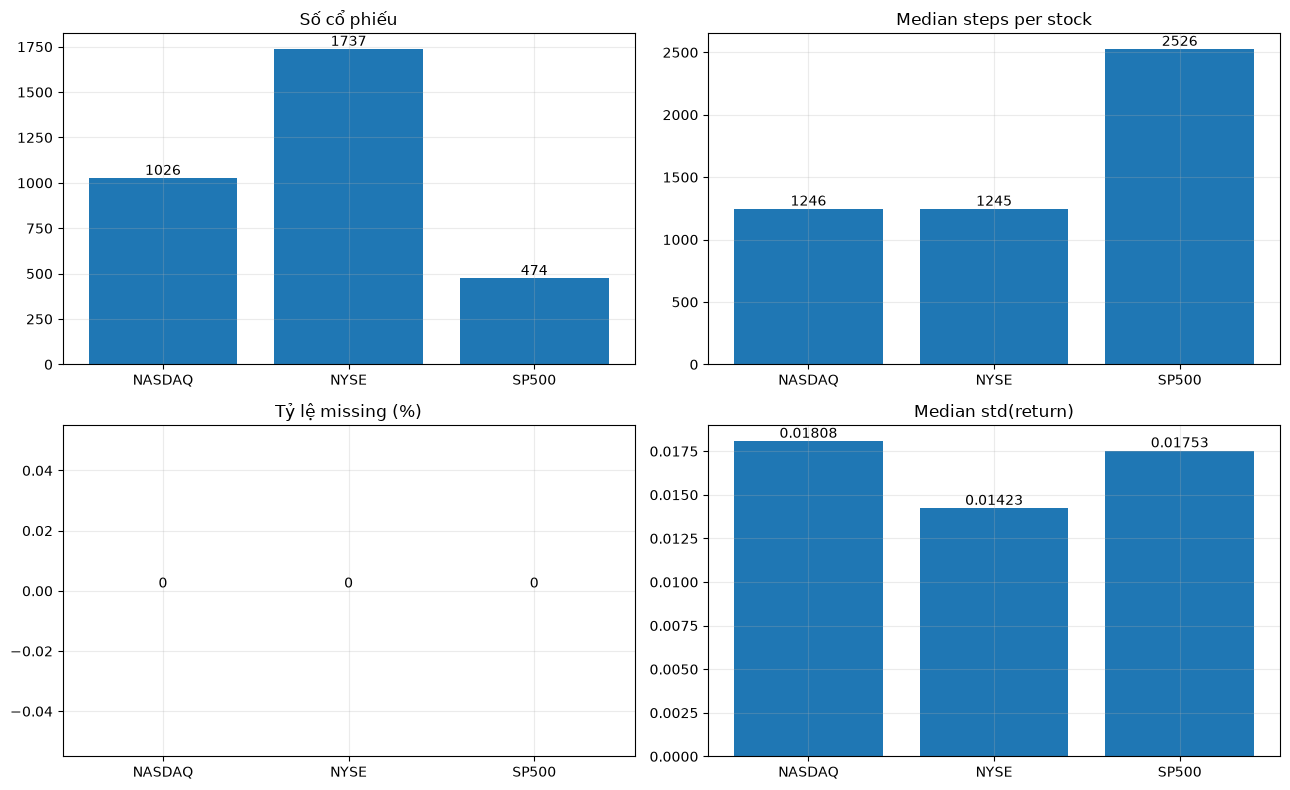

### Overlap giữa **danh sách ticker** (không suy ra tensor index)

,NASDAQ,NYSE,SP500_metadata
NASDAQ,1026,0,109
NYSE,0,1737,308
SP500_metadata,109,308,505


In [14]:
all3=pd.concat([x for x in MARKET_STATS.values() if not x.empty],ignore_index=True)
comp=all3.groupby('dataset').agg(
    n_stocks=('ticker','size'),
    total_rows=('rows','sum'),
    median_steps=('rows','median'),
    n_features_min=('n_features','min'),
    n_features_max=('n_features','max'),
    missing_pct=('missing_fraction',lambda s:100*s.mean()),
    zero_pct=('zero_fraction',lambda s:100*s.mean()),
    median_daily_return=('daily_return_mean','median'),
    median_daily_volatility=('daily_return_std','median'),
    median_positive_rate=('positive_return_rate','median'),
    median_drawdown=('max_drawdown','median'),
    median_outlier_rate=('outlier_20pct_rate','median'),
    median_return_autocorr=('return_autocorr_lag1','median')
).reset_index()
display(comp.round(5))
report('10_cross_dataset_comparison',comp)
fig,ax=plt.subplots(2,2,figsize=(13,8))
plots=[('n_stocks','Số cổ phiếu'),('median_steps','Median steps per stock'),
       ('missing_pct','Tỷ lệ missing (%)'),('median_daily_volatility','Median std(return)')]
for a,(col,title) in zip(ax.flat,plots):
    a.bar(comp['dataset'],comp[col]);a.set_title(title)
    for i,v in enumerate(comp[col]):a.annotate(f'{v:.4g}',(i,v),ha='center',va='bottom')
savefig('12_three_dataset_comparison')

# Danh sách mã chung: NASDAQ / NYSE và DANH SÁCH SP500, không gán thứ tự tensor.
na=set(MARKET_STATS['NASDAQ']['ticker']);ny=set(MARKET_STATS['NYSE']['ticker'])
spmeta=set(META['Symbol'].astype(str)) if 'Symbol' in META else set()
sets={'NASDAQ':na,'NYSE':ny,'SP500_metadata':spmeta}
overlap=pd.DataFrame([[len(sets[a]&sets[b]) for b in sets] for a in sets],
                     index=sets.keys(),columns=sets.keys())
display(Markdown('### Overlap giữa **danh sách ticker** (không suy ra tensor index)'))
display(overlap)
report('10_ticker_overlap',overlap.reset_index().rename(columns={'index':'dataset'}))
common_tickers=pd.DataFrame({'ticker':sorted(spmeta&(na|ny))})
report('10_sp500_vs_nasdaq_nyse_common_tickers',common_tickers,sort_by='ticker',ascending=True)

## 13. Cấu trúc dự báo ML: target, imbalance, drift và leakage

Với mỗi dataset, tạo target minh họa: `target_direction_1d = 1(return t→t+1 > 0)`. **Không coi target bằng 0 (không tăng) là giảm** nếu không có giá hợp lệ; return = 0 được tính riêng. Chia dữ liệu theo thời gian 70/15/15 **chỉ để chẩn đoán**, tránh random split. Kiểm tra distribution shift giữa đầu/cuối giai đoạn và baseline dự đoán chiều tăng theo đa số lớp.

,dataset,split,time_steps,n_valid_target_obs,up_rate,down_rate,unchanged_rate,majority_class_rate,return_mean,return_std,return_median,return_q01,return_q99
0,NASDAQ,train,872,892129,0.50691,0.47718,0.01591,0.50691,0.00055,0.02080,0.00035,-0.05368,0.05747
1,NASDAQ,val,187,191273,0.52052,0.45776,0.02172,0.52052,0.00116,0.02028,0.00073,-0.05255,0.05599
2,NASDAQ,test,187,191266,0.50934,0.46316,0.02751,0.50934,0.00062,0.01953,0.00039,-0.04994,0.05098
3,NYSE,train,871,1509970,0.50355,0.47145,0.02501,0.50355,0.00025,0.01663,0.00024,-0.04528,0.04589
4,NYSE,val,187,324585,0.51186,0.46124,0.02690,0.51186,0.00057,0.01662,0.00047,-0.04579,0.04530
5,NYSE,test,187,324571,0.50874,0.45608,0.03518,0.50874,0.00040,0.01500,0.00037,-0.04022,0.03976
6,SP500,train,1768,837558,0.52100,0.46581,0.01320,0.52100,0.00061,0.01625,0.00065,-0.04348,0.04315
7,SP500,val,379,179646,0.52769,0.46805,0.00426,0.52769,0.00084,0.02968,0.00111,-0.08663,0.09122
8,SP500,test,379,179646,0.51663,0.47928,0.00410,0.51663,0.00057,0.01991,0.00063,-0.05279,0.05367


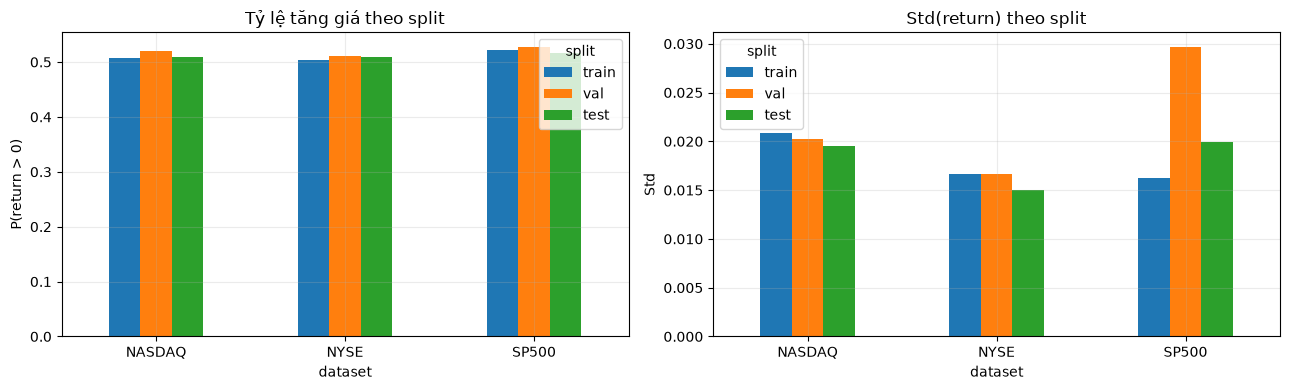

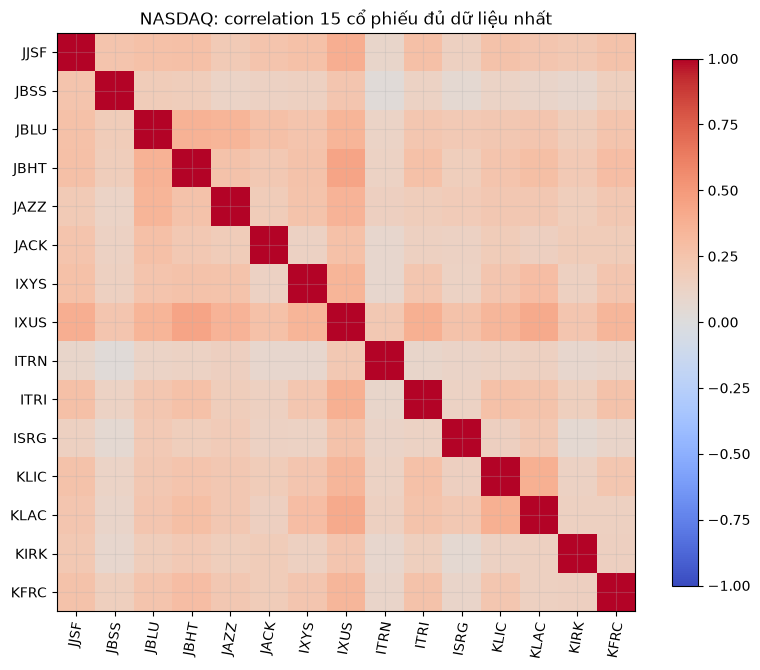

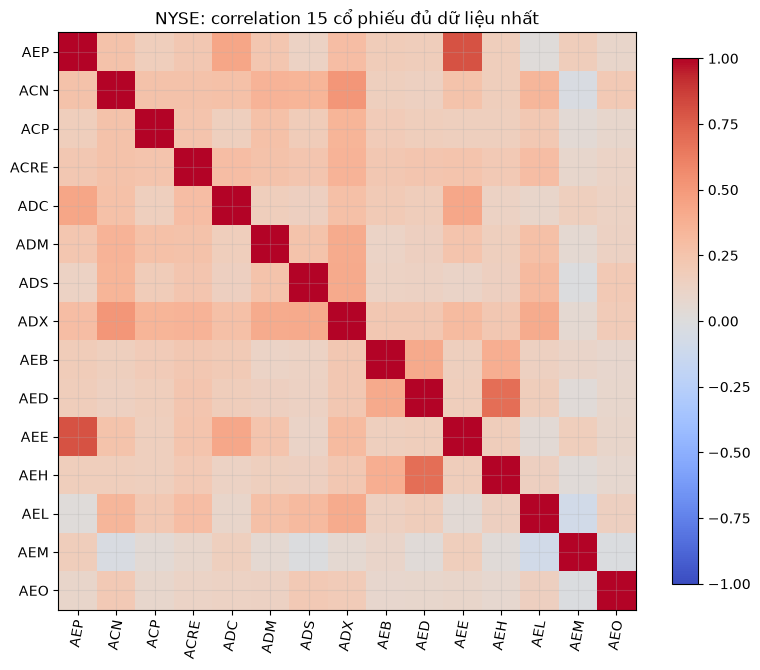

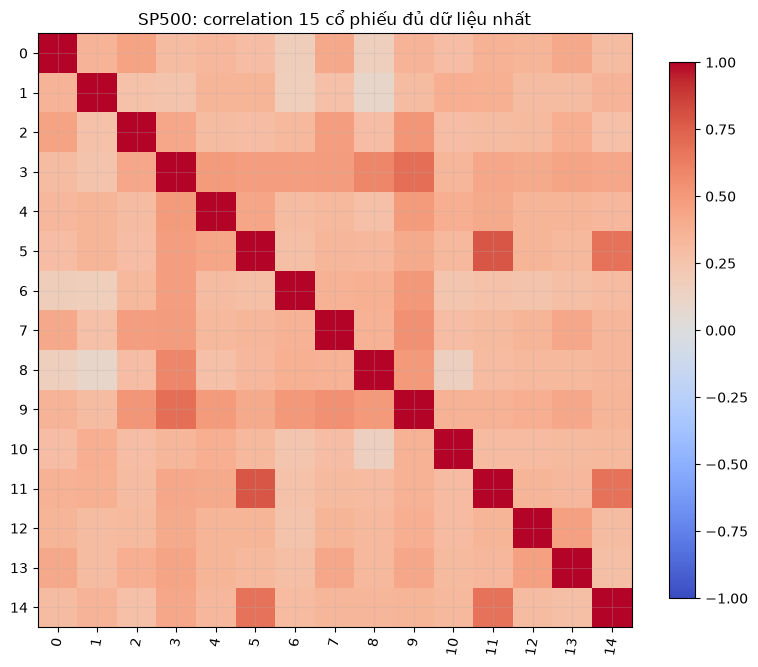

In [15]:
def period_diagnostics(market):
    obj=MATRICES[market]
    returns=obj['returns']
    T=returns.shape[1]
    p0,p1=int(T*.7),int(T*.85)
    splits={'train':returns[:,:p0], 'val':returns[:,p0:p1], 'test':returns[:,p1:]}
    res=[]
    for part,chunk in splits.items():
        valid=np.isfinite(chunk)
        vals=chunk[valid]
        if len(vals)==0:continue
        pos=float(np.mean(vals>0));neg=float(np.mean(vals<0));flat=float(np.mean(vals==0))
        mean=float(np.mean(vals)); std=float(np.std(vals))
        res.append({'dataset':market,'split':part,'time_steps':chunk.shape[1],
                    'n_valid_target_obs':len(vals),'up_rate':pos,'down_rate':neg,
                    'unchanged_rate':flat,'majority_class_rate':max(pos,1-pos),
                    'return_mean':mean,'return_std':std,
                    'return_median':float(np.median(vals)),
                    'return_q01':float(np.quantile(vals,.01)),
                    'return_q99':float(np.quantile(vals,.99))})
    return pd.DataFrame(res)
if MATRICES:
    DIAGNOSTICS=pd.concat([period_diagnostics(m) for m in MATRICES],ignore_index=True)
    display(DIAGNOSTICS.round(5))
    report('11_ml_temporal_split_diagnostics',DIAGNOSTICS)
    fig,ax=plt.subplots(1,2,figsize=(13,4))
    pivot=DIAGNOSTICS.pivot(index='dataset',columns='split',values='up_rate').reindex(columns=['train','val','test'])
    pivot.plot.bar(ax=ax[0],rot=0);ax[0].set(title='Tỷ lệ tăng giá theo split',ylabel='P(return > 0)')
    pivot2=DIAGNOSTICS.pivot(index='dataset',columns='split',values='return_std').reindex(columns=['train','val','test'])
    pivot2.plot.bar(ax=ax[1],rot=0);ax[1].set(title='Std(return) theo split',ylabel='Std')
    savefig('13_temporal_split_drift')
    # Kiểm tra tương quan vài mã: cùng index, cùng nguồn dữ liệu.
    for market,ob in MATRICES.items():
        r=ob['returns'];valid=np.isfinite(r).sum(axis=1)
        top=np.argsort(-valid)[:min(15,len(valid))]
        c=pd.DataFrame(r[top].T,columns=[ob['tickers'][i] for i in top]).corr(min_periods=25)
        fig,ax=plt.subplots(figsize=(8,7));im=ax.imshow(c,cmap='coolwarm',vmin=-1,vmax=1)
        ax.set(xticks=np.arange(len(c)),yticks=np.arange(len(c)),
               xticklabels=c.columns,yticklabels=c.columns,
               title=f'{market}: correlation 15 cổ phiếu đủ dữ liệu nhất')
        ax.tick_params(axis='x',rotation=80)
        fig.colorbar(im,ax=ax,shrink=.8)
        savefig(f'14_{market.lower()}_stock_return_corr')
        report(f'11_{market.lower()}_stock_return_correlations',c.reset_index().rename(columns={'index':'ticker'}))

## 14. Báo cáo tự động: dấu hiệu cần xử lý và dữ liệu nên dùng cho mô hình

Bảng dưới đây là **cảnh báo kiểm tra**, không phải kết luận nguyên nhân. Mốc `>20%/bước` chỉ để flag bất thường; có thể là sự kiện giá thực, lỗi chuẩn hóa hoặc missing masking.

In [16]:
checks=[]
for market,t in MARKET_STATS.items():
    if t.empty:continue
    checks.extend([
        {'dataset':market,'check':'missing ở ít nhất một feature','affected_stocks':int((t.missing_fraction>0).sum()),
         'action':'Kiểm tra missing mask, không forward-fill trước split một cách tùy tiện'},
        {'dataset':market,'check':'time_index trùng','affected_stocks':int((t.duplicate_time_index>0).sum()),
         'action':'Rà soát thứ tự và các quan sát bị lặp'},
        {'dataset':market,'check':'price_proxy không dương trên một số bước',
         'affected_stocks':int((t.price_proxy_positive_fraction<1).sum()),
         'action':'Xác minh 0 là missing hay giá trị hợp lệ; return phải mask'},
        {'dataset':market,'check':'return outlier abs >= 20%',
         'affected_stocks':int((t.outlier_20pct_rate>0).sum()),
         'action':'Kiểm tra split/dividend, chất lượng và định nghĩa kênh giá'},
        {'dataset':market,'check':'độ dài chuỗi dưới 90% median',
         'affected_stocks':int((t.rows < .9*t.rows.median()).sum()),
         'action':'Chọn coverage criteria và xây dựng mask riêng'},
    ])
CHECKS=pd.DataFrame(checks)
display(CHECKS)
report('12_data_quality_action_items',CHECKS,sort_by='affected_stocks')

print('KẾT LUẬN PHƯƠNG PHÁP LUẬN:')
print('1. Nên xây target return 1 ngày bằng ratio, KHÔNG dự đoán raw normalized features nếu mục tiêu stock movement.')
print('2. Chia train/val/test theo thời gian, fit scaler trên TRAIN, tuyệt đối không shuffle theo từng row.')
print('3. NASDAQ/NYSE thiếu calendar date trong file _1.csv: cần ánh xạ ngày từ nguồn gốc trước khi kết hợp dữ liệu ngoài.')
print('4. S&P500 có hai lớp: tensor preprocess và baseline OHLCV, chỉ map ticker index nếu kiểm tra được thứ tự.')
print('5. Các metric proxy xuyên nguồn là mô tả bước đầu, không đảm bảo tính so sánh hoàn toàn.')
print('6. Nếu dùng quan hệ industry/wiki cho NASDAQ/NYSE, cần tải thêm các relation files (script hiện tại chỉ tải chuỗi giá).')
print('7. Kiểm tra survivorship bias và normalize dùng toàn thời kỳ trước khi kết luận tính tổng quát của mô hình.')

,dataset,check,affected_stocks,action
0,NASDAQ,missing ở ít nhất một feature,0,"Kiểm tra missing mask, không forward-fill trướ..."
1,NASDAQ,time_index trùng,0,Rà soát thứ tự và các quan sát bị lặp
2,NASDAQ,price_proxy không dương trên một số bước,569,Xác minh 0 là missing hay giá trị hợp lệ; retu...
3,NASDAQ,return outlier abs >= 20%,307,"Kiểm tra split/dividend, chất lượng và định ng..."
4,NASDAQ,độ dài chuỗi dưới 90% median,0,Chọn coverage criteria và xây dựng mask riêng
5,NYSE,missing ở ít nhất một feature,0,"Kiểm tra missing mask, không forward-fill trướ..."
6,NYSE,time_index trùng,0,Rà soát thứ tự và các quan sát bị lặp
7,NYSE,price_proxy không dương trên một số bước,114,Xác minh 0 là missing hay giá trị hợp lệ; retu...
8,NYSE,return outlier abs >= 20%,241,"Kiểm tra split/dividend, chất lượng và định ng..."
9,NYSE,độ dài chuỗi dưới 90% median,0,Chọn coverage criteria và xây dựng mask riêng


KẾT LUẬN PHƯƠNG PHÁP LUẬN:
1. Nên xây target return 1 ngày bằng ratio, KHÔNG dự đoán raw normalized features nếu mục tiêu stock movement.
2. Chia train/val/test theo thời gian, fit scaler trên TRAIN, tuyệt đối không shuffle theo từng row.
3. NASDAQ/NYSE thiếu calendar date trong file _1.csv: cần ánh xạ ngày từ nguồn gốc trước khi kết hợp dữ liệu ngoài.
4. S&P500 có hai lớp: tensor preprocess và baseline OHLCV, chỉ map ticker index nếu kiểm tra được thứ tự.
5. Các metric proxy xuyên nguồn là mô tả bước đầu, không đảm bảo tính so sánh hoàn toàn.
6. Nếu dùng quan hệ industry/wiki cho NASDAQ/NYSE, cần tải thêm các relation files (script hiện tại chỉ tải chuỗi giá).
7. Kiểm tra survivorship bias và normalize dùng toàn thời kỳ trước khi kết luận tính tổng quát của mô hình.


## 15. Xuất toàn bộ biểu đồ + file kết quả, manifest

Các bảng CSV đã được xuất lần lượt ở những cell trước; cell cuối lưu `EDA_manifest.json` mô tả nơi lưu và số lượng mã thực sự đã được quét.

In [17]:
manifest={
    'project_root':str(PROJECT_ROOT),
    'data_root':str(DATA_ROOT),
    'figure_directory':str(FIG_DIR),
    'report_directory':str(REPORT_DIR),
    'parameters':{'max_tickers_per_market':MAX_TICKERS_PER_MARKET,
                  'sample_rows_per_stock':SAMPLE_ROWS_PER_STOCK,
                  'outlier_abs_return_threshold':OUTLIER_RETURN_THRESHOLD},
    'stock_counts':{k:len(v) for k,v in MARKET_STATS.items()},
    'figures':FIGURES_SAVED,
    'reports':[p.name for p in sorted(REPORT_DIR.glob('*.csv'))],
    'notices':['NASDAQ/NYSE CSV: time_index, 5 preprocessed features, no OHLCV/calendar date.',
               'SP500 tensor stock_index not guaranteed to align with metadata ticker order.',
               'price_proxy last channel follows repository modeling convention, not guaranteed original USD price.',
               'baseline pickle intentionally not loaded for security.']}
with (REPORT_DIR/'EDA_manifest.json').open('w',encoding='utf-8') as f:
    json.dump(manifest,f,ensure_ascii=False,indent=2)
print('✅ Hoàn tất EDA')
print(f'  {len(FIGURES_SAVED)} ảnh -> {FIG_DIR}')
print(f'  {len(manifest["reports"])} bảng CSV -> {REPORT_DIR}')
print('  Manifest:', REPORT_DIR/'EDA_manifest.json')

✅ Hoàn tất EDA
  25 ảnh -> D:\NCKH\PTDLKD\Anh\EDA
  26 bảng CSV -> D:\NCKH\PTDLKD\Anh\EDA\reports
  Manifest: D:\NCKH\PTDLKD\Anh\EDA\reports\EDA_manifest.json
